# SAMS Vision: accident (fall) detection training

This notebook trains the YOLOv8 detector that SAMS uses to spot a worker who has fallen and is lying on the floor. The live service (`monitoring/services/accident_inference.py`) loads `models/vision/accident/best.pt` and reads its settings from `models/vision/accident/metadata.json`. This notebook writes both files.

## What the model has to do

The live service runs this detector on each camera frame and keeps only the boxes whose class is listed in `fall_classes` (`detect_falls`). A tracked worker is marked fallen when one of those boxes overlaps the worker's person box (`fall_for_box`). Pose angle is not used. The detector therefore has to tell a lying person from a standing one, seen from a high CCTV angle.

| id | Class | Role in SAMS |
|----|-------|--------------|
| 0 | laying | Fall class. Listed in `fall_classes`, raises the alarm |
| 1 | standing | Negative class. Teaches the model what a person who has not fallen looks like. Ignored by the live service |

The service reads four keys from `metadata.json`: `model_id`, `fall_classes`, `conf`, and `imgsz`. `conf` is passed to `predict`, and only fall-class boxes are kept afterwards, so `conf` works as the threshold of the `laying` class.

## Data source

| Short name | Source | What it shows | Why it is used |
|------------|--------|---------------|----------------|
| sim | [Simuletic CCTV Incident Dataset, Fall / Lying Down Detection](https://huggingface.co/datasets/Simuletic/CCTV_Incident_Dataset_Fall_Lying_Down_Detection), Hugging Face, CC BY 4.0 | About 110 synthetic overhead CCTV scenes. Nearly every image has a person lying on the floor, and a few also have a standing person | Public fall labels from a CCTV angle, which is the angle SAMS cameras have |

The labels are in YOLO-pose format: class, box, and 17 COCO keypoints. Only the class and the box are kept. The published dataset file points train and val at the same folder, so this notebook makes its own splits. There is one source, so a leave-one-source-out check does not apply.

## Steps

| Section | Step |
|---------|------|
| 0 | Setup, configuration, class list, helper functions |
| 1 | Download the dataset and turn the pose labels into box labels |
| 2 | Preview the dataset, all images and per class |
| 3 | Build one table of every image and a stratified 70/15/15 train/val/test split |
| 4 | Exploratory data analysis |
| 5 | PCA of image-level features and person crops |
| 6 | Build the training set; augment train only if laying is scarce |
| 7 | Training setup: hyperparameters, early stopping, two-stage fine-tuning |
| 8 | Experiments E1 through E5, one change at a time |
| 9 | Compare experiments, choose the model, repeat with seeds 1 and 2 |
| 10 | Detailed val evaluation |
| 11 | Final test, metadata, export check, model card |
| 12 | Limitations and next steps |

## Rules this notebook follows

1. Val and test hold only original dataset images. They are never augmented or copied.
2. Train/val/test are stratified by whether the image contains a laying box (seed 42). Val and test are never augmented.
3. Augmentation applies to train only when laying boxes are scarce.
4. Each experiment changes one thing compared with the one before it, so every gain can be explained.
5. The model is chosen on val. The test split is scored once, after the choice.
6. Every table is shown as a pandas DataFrame and saved as a CSV file. Every chart is saved as a PNG file.

## 0. Setup

### 0.1 Paths

The notebook runs in Google Colab or locally. In Colab, data is unpacked on the fast local disk (`/content/SAMS`) and models and results are saved to Google Drive so they survive a disconnect. Locally, the project root is used, so the weights land where `accident_inference.py` looks for them.

In [ ]:
from pathlib import Path

IN_COLAB = False
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    SAMS_ROOT = Path("/content/SAMS")
else:
    SAMS_ROOT = Path("./SAMS_runtime")

for folder in [
    SAMS_ROOT / "datasets" / "vision" / "accident",
    SAMS_ROOT / "models" / "vision" / "accident",
    SAMS_ROOT / "results" / "vision" / "accident",
]:
    folder.mkdir(parents=True, exist_ok=True)

print("SAMS_ROOT:", SAMS_ROOT.resolve())

Running in Colab: True
SAMS_ROOT: /content/SAMS


In [ ]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/SAMS")
else:
    here = Path.cwd().resolve()
    if (here / "manage.py").exists():
        DRIVE_ROOT = here
    elif (here.parent / "manage.py").exists():
        DRIVE_ROOT = here.parent
    else:
        DRIVE_ROOT = Path("./SAMS_drive_mirror")

MODELS_DIR = DRIVE_ROOT / "models" / "vision" / "accident"
RESULTS_DIR = DRIVE_ROOT / "results" / "vision" / "accident"
DATA_DIR = SAMS_ROOT / "datasets" / "vision" / "accident"

for folder in [MODELS_DIR, RESULTS_DIR, DATA_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("MODELS_DIR: ", MODELS_DIR)
print("RESULTS_DIR:", RESULTS_DIR)
print("DATA_DIR:   ", DATA_DIR)

Mounted at /content/drive
MODELS_DIR:  /content/drive/MyDrive/SAMS/models/vision/accident
RESULTS_DIR: /content/drive/MyDrive/SAMS/results/vision/accident
DATA_DIR:    /content/SAMS/datasets/vision/accident


### 0.2 Packages

`albumentations` 2.x is required because the augmentation steps use its newer argument names (`std_range`, `quality_range`, `scale_range`, `fog_coef_range`). `onnx` and `onnxruntime` are only used for the export check in section 11.

In [ ]:
import subprocess
import sys

PACKAGES = [
    "ultralytics>=8.3.0",
    "albumentations>=2.0.0",
    "huggingface_hub",
    "scikit-learn",
    "seaborn",
    "pandas",
    "matplotlib",
    "pyyaml",
    "Pillow",
    "onnx",
    "onnxruntime",
]

if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *PACKAGES])
    print("Packages installed.")
else:
    print("Not in Colab. Install these packages in your environment if an import fails:")
    print(PACKAGES)

Packages installed.


In [ ]:
import gc
import hashlib
import json
import random
import re
import shutil
import time
import warnings
from collections import Counter
from datetime import datetime, timezone

import albumentations as A
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
import torchvision
import ultralytics
import yaml
from huggingface_hub import snapshot_download
from IPython.display import display
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from ultralytics import YOLO

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

version_table = pd.DataFrame([
    {"package": "ultralytics", "version": ultralytics.__version__},
    {"package": "torch", "version": torch.__version__},
    {"package": "torchvision", "version": torchvision.__version__},
    {"package": "albumentations", "version": A.__version__},
    {"package": "scikit-learn", "version": sklearn.__version__},
    {"package": "pandas", "version": pd.__version__},
    {"package": "numpy", "version": np.__version__},
])
display(version_table)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


,package,version
0,ultralytics,8.4.174
1,torch,2.11.0+cu130
2,torchvision,0.26.0+cu130
3,albumentations,2.0.8
4,scikit-learn,1.6.1
5,pandas,2.2.3
6,numpy,2.1.3


### 0.3 Configuration

Every setting that changes the result is in this one cell, with its meaning in the table below. Change a value here and rerun the notebook. Nothing further down hides its own constants.

The dataset is small (about 110 images) and the `standing` class has only about ten boxes, so several settings are smaller than in the PPE notebook: the target per class, the number of copies per photo, and the val and test shares. `WINNER_TOLERANCE` is 0.005: if two runs are that close on val mAP50-95, the one with higher `laying` recall wins.

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

HAS_GPU = torch.cuda.is_available()
if HAS_GPU:
    YOLO_DEVICE = 0
    TORCH_DEVICE = "cuda"
else:
    YOLO_DEVICE = "cpu"
    TORCH_DEVICE = "cpu"

# Data
DATASET_REPO = "Simuletic/CCTV_Incident_Dataset_Fall_Lying_Down_Detection"
DATASET_URL = "https://huggingface.co/datasets/" + DATASET_REPO
VAL_FRACTION = 0.15
TEST_FRACTION = 0.15
NEAR_DUP_HAMMING = 10
SCENE_CORRELATION = 0.90
MIN_EVAL_BOXES = 10
EXTRA_BACKGROUND_DIR = DRIVE_ROOT / "datasets" / "vision" / "accident" / "background"

# Balancing, training split only
TARGET_BOXES_PER_CLASS = 80
BACKGROUND_FRACTION = 0.10
BACKGROUND_MIN_SIDE = 0.25
MAX_COPIES_PER_IMAGE = 6

# Training
MAX_EPOCHS = 25
PATIENCE = 3
STAGE_A_EPOCHS = 10
FREEZE_LAYERS = 10
if HAS_GPU:
    BATCH = 16
else:
    BATCH = 4
IMGSZ_BASE = 640
IMGSZ_LARGE = 960
SELECTION_METRIC = "map50_95"
WINNER_TOLERANCE = 0.005

# Evaluation
FALL_MIN_RECALL = 0.90
MATCH_IOU = 0.50
BOOTSTRAP_ROUNDS = 1000
REPEAT_SEEDS = [1, 2]
CROP_PADDING = 0.10
TIMING_IMAGES = 100

config_rows = [
    {"setting": "SEED", "value": SEED, "meaning": "Random seed for splitting, augmentation, and training"},
    {"setting": "YOLO_DEVICE", "value": YOLO_DEVICE, "meaning": "0 is the first GPU, cpu means no GPU"},
    {"setting": "DATASET_REPO", "value": DATASET_REPO, "meaning": "Hugging Face dataset that is downloaded"},
    {"setting": "VAL_FRACTION", "value": VAL_FRACTION, "meaning": "Share of images held out for val (stratified by laying presence)"},
    {"setting": "TEST_FRACTION", "value": TEST_FRACTION, "meaning": "Share of images held out for test (stratified by laying presence)"},
    {"setting": "NEAR_DUP_HAMMING", "value": NEAR_DUP_HAMMING, "meaning": "Images whose 64-bit hashes differ in at most this many bits are the same scene"},
    {"setting": "SCENE_CORRELATION", "value": SCENE_CORRELATION, "meaning": "Consecutive frames whose thumbnails correlate at least this much are the same scene"},
    {"setting": "MIN_EVAL_BOXES", "value": MIN_EVAL_BOXES, "meaning": "Fewest real boxes a class should have in val and in test"},
    {"setting": "EXTRA_BACKGROUND_DIR", "value": str(EXTRA_BACKGROUND_DIR), "meaning": "Folder for your own empty SAMS frames. Leave it empty if you have none"},
    {"setting": "TARGET_BOXES_PER_CLASS", "value": TARGET_BOXES_PER_CLASS, "meaning": "Training boxes each class should reach after balancing"},
    {"setting": "BACKGROUND_FRACTION", "value": BACKGROUND_FRACTION, "meaning": "Background images to add, as a share of the real training images"},
    {"setting": "BACKGROUND_MIN_SIDE", "value": BACKGROUND_MIN_SIDE, "meaning": "Smallest width and height, as a share of the image, of a person-free crop"},
    {"setting": "MAX_COPIES_PER_IMAGE", "value": MAX_COPIES_PER_IMAGE, "meaning": "Most augmented copies made from one real photo"},
    {"setting": "MAX_EPOCHS", "value": MAX_EPOCHS, "meaning": "Upper limit on epochs. Early stopping usually ends sooner"},
    {"setting": "PATIENCE", "value": PATIENCE, "meaning": "Epochs without a val improvement before training stops"},
    {"setting": "STAGE_A_EPOCHS", "value": STAGE_A_EPOCHS, "meaning": "Epochs with the backbone frozen in two-stage fine-tuning"},
    {"setting": "FREEZE_LAYERS", "value": FREEZE_LAYERS, "meaning": "Layers frozen in stage A. 10 is the whole YOLOv8 backbone"},
    {"setting": "BATCH", "value": BATCH, "meaning": "Images per training step. Fixed, because the dataset is smaller than an automatic batch"},
    {"setting": "IMGSZ_BASE", "value": IMGSZ_BASE, "meaning": "Default training image size"},
    {"setting": "IMGSZ_LARGE", "value": IMGSZ_LARGE, "meaning": "Larger size tested for people far from the camera"},
    {"setting": "SELECTION_METRIC", "value": SELECTION_METRIC, "meaning": "Val score used to choose between experiments: overall mAP50-95"},
    {"setting": "WINNER_TOLERANCE", "value": WINNER_TOLERANCE, "meaning": "Runs this close to the best score count as tied. Ties go to higher laying recall"},
    {"setting": "FALL_MIN_RECALL", "value": FALL_MIN_RECALL, "meaning": "Recall wanted on the laying class when its threshold is chosen"},
    {"setting": "MATCH_IOU", "value": MATCH_IOU, "meaning": "Overlap needed for a prediction to count as finding a label"},
    {"setting": "BOOTSTRAP_ROUNDS", "value": BOOTSTRAP_ROUNDS, "meaning": "Resampling rounds for the confidence intervals"},
    {"setting": "REPEAT_SEEDS", "value": str(REPEAT_SEEDS), "meaning": "Extra seeds used to retrain the chosen recipe"},
    {"setting": "CROP_PADDING", "value": CROP_PADDING, "meaning": "Extra margin around a person box when it is cropped for PCA"},
    {"setting": "TIMING_IMAGES", "value": TIMING_IMAGES, "meaning": "Single-image predictions timed in the export check"},
]
config_table = pd.DataFrame(config_rows).set_index("setting")
config_table.to_csv(RESULTS_DIR / "config.csv")
display(config_table)

,value,meaning
setting,,
SEED,42,"Random seed for splitting, augmentation, and t..."
YOLO_DEVICE,0,"0 is the first GPU, cpu means no GPU"
DATASET_REPO,Simuletic/CCTV_Incident_Dataset_Fall_Lying_Dow...,Hugging Face dataset that is downloaded
VAL_FRACTION,0.15,Share of images held out for val (stratified b...
TEST_FRACTION,0.15,Share of images held out for test (stratified ...
NEAR_DUP_HAMMING,10,Images whose 64-bit hashes differ in at most t...
SCENE_CORRELATION,0.9,Consecutive frames whose thumbnails correlate ...
MIN_EVAL_BOXES,10,Fewest real boxes a class should have in val a...
EXTRA_BACKGROUND_DIR,/content/drive/MyDrive/SAMS/datasets/vision/ac...,Folder for your own empty SAMS frames. Leave i...


### 0.4 Class list

The class ids are the ones the dataset publishes, so they are not remapped. `FALL_CLASSES` is written to `metadata.json` as `fall_classes`. `norm_name` is the same name normalisation the live service applies (`_norm` in `accident_inference.py`: lower case, dashes and underscores become spaces), so the check in section 11 compares names the way the service does.

In [ ]:
CLASS_NAMES = {
    0: "laying",
    1: "standing",
}
NUM_CLASSES = len(CLASS_NAMES)

NAME_TO_ID = {}
for class_id, class_name in CLASS_NAMES.items():
    NAME_TO_ID[class_name] = class_id

FALL_CLASS = "laying"
FALL_ID = NAME_TO_ID[FALL_CLASS]
FALL_CLASSES = [FALL_CLASS]
BALANCE_CLASSES = list(CLASS_NAMES.values())


def norm_name(value):
    text = str(value).strip().lower()
    text = text.replace("-", " ").replace("_", " ")
    return " ".join(text.split())


class_rows = []
for class_id, class_name in CLASS_NAMES.items():
    if class_name in FALL_CLASSES:
        role = "fall class, raises the alarm"
    else:
        role = "negative class, ignored by the live service"
    class_rows.append({
        "id": class_id,
        "class": class_name,
        "role": role,
        "balanced in training": class_name in BALANCE_CLASSES,
    })
display(pd.DataFrame(class_rows).set_index("id"))

,class,role,balanced in training
id,,,
0,laying,"fall class, raises the alarm",True
1,standing,"negative class, ignored by the live service",True


### 0.5 Helper functions

All images are copied into one staging folder, `merged/`, with this layout:

| Folder | Holds |
|--------|-------|
| `images/all` | Every dataset image. Train, val, and test are chosen from here |
| `images/background` | Background images with no person: your own frames and person-free crops, made in section 6 |
| `images/aug` | Augmented training copies, made in section 6 |
| `images/robust_*` | Degraded copies of val images for the robustness test in section 10 |
| `labels/...` | One YOLO label file per image, in the matching folder |

Training sets, val, and test are then written as text files that list image paths. Ultralytics accepts these lists, so no image is copied twice. Ultralytics finds each label by swapping `images` for `labels` in the path, which is why the two folder trees mirror each other.

Each label line is `class x_center y_center width height`, with the four box values divided by the image width or height so they lie between 0 and 1.

Two kinds of image fingerprint are used in sections 3 to 5:

- `hash_bits` is a difference hash. The image is shrunk to 9 by 8 grey pixels, and each of the 64 bits records whether a pixel is brighter than its right-hand neighbour. The number of differing bits (Hamming distance) between two images is small when they look the same.
- `thumbnail` is a 32 by 32 grey copy, scaled to mean 0 and standard deviation 1. The mean product of two thumbnails is their correlation: 1.0 means the same picture.

In [ ]:
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp"}
MERGED = DATA_DIR / "merged"
LISTS_DIR = MERGED / "lists"


def list_images(folder):
    found = []
    folder = Path(folder)
    if not folder.exists():
        return found
    for path in sorted(folder.iterdir()):
        if path.suffix.lower() in IMAGE_SUFFIXES:
            found.append(path)
    return found


def label_path_for(image_path):
    image_path = Path(image_path)
    folder = image_path.parent.name
    return MERGED / "labels" / folder / f"{image_path.stem}.txt"


def read_labels(label_path):
    """Read a YOLO label file into rows of [class_id, xc, yc, w, h].

    Pose label lines carry 17 keypoints after the box. Only the first five values are read.
    """
    rows = []
    label_path = Path(label_path)
    if not label_path.is_file():
        return rows
    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) < 5:
            continue
        class_id = int(float(parts[0]))
        xc = float(parts[1])
        yc = float(parts[2])
        w = float(parts[3])
        h = float(parts[4])
        rows.append([class_id, xc, yc, w, h])
    return rows


def clean_box(xc, yc, w, h):
    """Clip a box to the image. Return None if almost nothing is left."""
    x1 = max(0.0, xc - w / 2)
    y1 = max(0.0, yc - h / 2)
    x2 = min(1.0, xc + w / 2)
    y2 = min(1.0, yc + h / 2)
    new_w = x2 - x1
    new_h = y2 - y1
    if new_w < 0.003 or new_h < 0.003:
        return None
    return [(x1 + x2) / 2, (y1 + y2) / 2, new_w, new_h]


def write_labels(label_path, rows):
    """Write rows of [class_id, xc, yc, w, h]. An empty file means a background image."""
    label_path = Path(label_path)
    label_path.parent.mkdir(parents=True, exist_ok=True)
    lines = []
    for row in rows:
        box = clean_box(row[1], row[2], row[3], row[4])
        if box is None:
            continue
        lines.append(f"{int(row[0])} {box[0]:.6f} {box[1]:.6f} {box[2]:.6f} {box[3]:.6f}")
    text = ""
    if lines:
        text = "\n".join(lines) + "\n"
    label_path.write_text(text)
    return len(lines)


def stage_image(source_image, rows, folder, prefix=""):
    """Copy one image into merged/images/<folder> and write its labels."""
    source_image = Path(source_image)
    target_image = MERGED / "images" / folder / f"{prefix}{source_image.name}"
    target_image.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source_image, target_image)
    write_labels(label_path_for(target_image), rows)
    return target_image


def write_list(name, image_paths):
    """Write a text file with one image path per line, for Ultralytics."""
    LISTS_DIR.mkdir(parents=True, exist_ok=True)
    path = LISTS_DIR / f"{name}.txt"
    lines = []
    for image_path in image_paths:
        lines.append(str(image_path))
    path.write_text("\n".join(lines) + "\n")
    return path


def read_list(list_path):
    paths = []
    for line in Path(list_path).read_text().splitlines():
        if line.strip():
            paths.append(Path(line.strip()))
    return paths


def class_counts_for_images(image_paths):
    counts = Counter()
    for image_path in image_paths:
        for row in read_labels(label_path_for(image_path)):
            counts[row[0]] += 1
    return counts


def counts_table(named_counters, classes=None):
    """One row per class, one column per Counter of class ids."""
    if classes is None:
        classes = list(CLASS_NAMES.values())
    table = pd.DataFrame(index=classes)
    for column, counter in named_counters.items():
        values = []
        for class_name in classes:
            values.append(int(counter.get(NAME_TO_ID[class_name], 0)))
        table[column] = values
    table.index.name = "class"
    return table


def size_bucket(w, h, width, height, train_size=IMGSZ_BASE):
    """Small, medium, or large, measured after the image is resized for training."""
    scale = train_size / max(width, height)
    area = (w * width * scale) * (h * height * scale)
    if area < 32 * 32:
        return "small"
    if area < 96 * 96:
        return "medium"
    return "large"


def shape_bucket(aspect):
    """Tall, square, or wide, from box width divided by box height in pixels."""
    if aspect < 0.8:
        return "tall"
    if aspect <= 1.25:
        return "square"
    return "wide"


CLASS_COLORS = {0: "#c53030", 1: "#2b6cb0"}


def draw_boxes(ax, image_path, rows, title="", color=None):
    """Draw [class_id, xc, yc, w, h] rows on an image."""
    image = Image.open(image_path).convert("RGB")
    width, height = image.size
    ax.imshow(image)
    for row in rows:
        class_id = row[0]
        left = (row[1] - row[3] / 2) * width
        top = (row[2] - row[4] / 2) * height
        box_color = color
        if box_color is None:
            box_color = CLASS_COLORS[class_id]
        rectangle = patches.Rectangle(
            (left, top), row[3] * width, row[4] * height,
            fill=False, linewidth=2, edgecolor=box_color,
        )
        ax.add_patch(rectangle)
        ax.text(left, top, CLASS_NAMES[class_id], color="white", fontsize=7, backgroundcolor=box_color)
    ax.set_title(title, fontsize=9)
    ax.axis("off")


def save_figure(fig, name):
    path = RESULTS_DIR / f"{name}.png"
    fig.savefig(path, dpi=140, bbox_inches="tight")
    plt.show()
    print("Saved figure:", path)


def save_table(frame, name):
    frame.to_csv(RESULTS_DIR / f"{name}.csv")
    display(frame)


def preview_images(image_paths, title, name, columns=4, rows=2, only_class=None):
    """Show a seeded random grid of images with their labels drawn.

    only_class limits the drawn boxes to one class id.
    """
    picks = []
    for image_path in image_paths:
        picks.append(Path(image_path))
    if not picks:
        display(pd.DataFrame([{"preview": title, "result": "no images"}]))
        return
    random.Random(SEED).shuffle(picks)
    picks = picks[:columns * rows]
    fig, axes = plt.subplots(rows, columns, figsize=(4.5 * columns, 4.2 * rows), squeeze=False)
    for ax in axes.flatten():
        ax.axis("off")
    for ax, image_path in zip(axes.flatten(), picks):
        rows_in_image = []
        for row in read_labels(label_path_for(image_path)):
            if only_class is None or row[0] == only_class:
                rows_in_image.append(row)
        draw_boxes(ax, image_path, rows_in_image, title=f"{image_path.name[:30]}  ({len(rows_in_image)} boxes)")
    fig.suptitle(title)
    plt.tight_layout()
    save_figure(fig, name)


def frame_number(image_path):
    """The last number in a file name such as laying42.png, or -1 if there is none."""
    digits = re.findall(r"\d+", Path(image_path).stem)
    if not digits:
        return -1
    return int(digits[-1])


def hash_bits(image_path):
    with Image.open(image_path) as image:
        small = image.convert("L").resize((9, 8))
    pixels = np.asarray(small, dtype=np.int16)
    brighter = pixels[:, 1:] > pixels[:, :-1]
    return brighter.flatten()


def bits_to_hex(bits):
    return np.packbits(bits).tobytes().hex()


def hamming(bits_a, bits_b):
    return int(np.count_nonzero(bits_a != bits_b))


def thumbnail(image_path, size=32):
    with Image.open(image_path) as image:
        small = image.convert("L").resize((size, size))
    pixels = np.asarray(small, dtype=np.float32).flatten()
    return (pixels - pixels.mean()) / (pixels.std() + 1e-6)


def thumb_correlation(thumb_a, thumb_b):
    return float(np.mean(thumb_a * thumb_b))


def crop_box(image, xc, yc, w, h, padding=CROP_PADDING):
    """Crop one box from an open PIL image, with a margin around it."""
    width, height = image.size
    half_w = w * width * (1 + padding) / 2
    half_h = h * height * (1 + padding) / 2
    center_x = xc * width
    center_y = yc * height
    left = max(0, int(center_x - half_w))
    top = max(0, int(center_y - half_h))
    right = min(width, int(center_x + half_w))
    bottom = min(height, int(center_y + half_h))
    return image.crop((left, top, right, bottom))


if MERGED.exists():
    shutil.rmtree(MERGED)
MERGED.mkdir(parents=True)
STAGED = []
print("Fresh staging folder:", MERGED)

Fresh staging folder: /content/SAMS/datasets/vision/accident/merged


## 1. Download the dataset and keep the boxes

The dataset is downloaded from Hugging Face with `snapshot_download`. Images are in `laying_dataset/images` and labels in `laying_dataset/labels`.

Each label line is `class xc yc w h` followed by 17 keypoints of 3 values each, so a full line has 56 values. Detection training uses only the first five. A line with an unknown class id is dropped, and the table shows how many.

If the publisher ships a dataset YAML file, its class names are checked against `CLASS_NAMES`. If they ever change, the notebook stops here instead of training a model whose class ids the live service would read wrongly.

In [ ]:
RAW_DIR = DATA_DIR / "cctv_fall_raw"
snapshot_download(
    repo_id=DATASET_REPO,
    repo_type="dataset",
    local_dir=str(RAW_DIR),
)

source_images_dir = RAW_DIR / "laying_dataset" / "images"
source_labels_dir = RAW_DIR / "laying_dataset" / "labels"
if not source_images_dir.is_dir():
    raise FileNotFoundError(source_images_dir)
if not source_labels_dir.is_dir():
    raise FileNotFoundError(source_labels_dir)

file_counter = Counter()
for path in RAW_DIR.rglob("*"):
    if not path.is_file() or ".cache" in path.parts:
        continue
    folder = str(path.parent.relative_to(RAW_DIR))
    file_counter[(folder, path.suffix.lower())] += 1

file_rows = []
for (folder, suffix), count in sorted(file_counter.items()):
    file_rows.append({"folder": folder, "file type": suffix, "files": count})
save_table(pd.DataFrame(file_rows).set_index("folder"), "download_files")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 226 files:   0%|          | 0/226 [00:00<?, ?it/s]

,file type,files
folder,,
.,,1
.,.md,1
laying_dataset,.png,1
laying_dataset,.yaml,1
laying_dataset/images,.png,111
laying_dataset/labels,.txt,111


In [ ]:
def names_as_dict(raw_names):
    names = {}
    if isinstance(raw_names, dict):
        for key, value in raw_names.items():
            names[int(key)] = str(value)
    else:
        for index, value in enumerate(raw_names):
            names[index] = str(value)
    return names


yaml_rows = []
for yaml_file in sorted(RAW_DIR.rglob("*.yaml")):
    content = yaml.safe_load(yaml_file.read_text())
    if not isinstance(content, dict) or "names" not in content:
        continue
    published = names_as_dict(content["names"])
    for class_id, class_name in published.items():
        if CLASS_NAMES.get(class_id) != class_name:
            raise RuntimeError(f"{yaml_file.name}: class {class_id} is {class_name}, expected {CLASS_NAMES.get(class_id)}")
    yaml_rows.append({"file": str(yaml_file.relative_to(RAW_DIR)), "names": str(published), "matches CLASS_NAMES": True})

if yaml_rows:
    display(pd.DataFrame(yaml_rows).set_index("file"))
else:
    display(pd.DataFrame([{"result": "No dataset YAML published. The class map from the README is used", "names": str(CLASS_NAMES)}]))

,names,matches CLASS_NAMES
file,,
laying_dataset/dataset.yaml,"{0: 'laying', 1: 'standing'}",True


In [ ]:
raw_images = list_images(source_images_dir)

values_per_line = Counter()
missing_label_files = 0
images_without_boxes = 0
unknown_class_lines = 0
boxes_kept = Counter()

for image_path in raw_images:
    label_file = source_labels_dir / f"{image_path.stem}.txt"
    if not label_file.is_file():
        missing_label_files += 1
    else:
        for line in label_file.read_text().splitlines():
            if line.strip():
                values_per_line[len(line.split())] += 1

    kept = []
    for row in read_labels(label_file):
        if row[0] not in CLASS_NAMES:
            unknown_class_lines += 1
            continue
        kept.append(row)
        boxes_kept[row[0]] += 1
    if not kept:
        images_without_boxes += 1

    target = stage_image(image_path, kept, "all")
    STAGED.append({"image": target, "original": image_path.name, "frame": frame_number(image_path)})

staging_summary = pd.DataFrame([
    {"item": "images downloaded", "value": len(raw_images)},
    {"item": "images without a label file", "value": missing_label_files},
    {"item": "images with no boxes", "value": images_without_boxes},
    {"item": "label lines with an unknown class", "value": unknown_class_lines},
    {"item": "laying boxes kept", "value": boxes_kept[NAME_TO_ID["laying"]]},
    {"item": "standing boxes kept", "value": boxes_kept[NAME_TO_ID["standing"]]},
]).set_index("item")
save_table(staging_summary, "staging_summary")

field_rows = []
for value_count, lines in sorted(values_per_line.items()):
    keypoints = (value_count - 5) / 3
    field_rows.append({"values per label line": value_count, "keypoints implied": keypoints, "lines": lines})
save_table(pd.DataFrame(field_rows).set_index("values per label line"), "label_line_format")

,value
item,
images downloaded,111
images without a label file,0
images with no boxes,0
label lines with an unknown class,0
laying boxes kept,111
standing boxes kept,10


,keypoints implied,lines
values per label line,,
56,17.0,121


The first label line of the first image, split into its parts. This confirms the box comes first and the keypoints after it.

In [ ]:
example_label = source_labels_dir / f"{raw_images[0].stem}.txt"
example_line = example_label.read_text().splitlines()[0].split()
example_rows = [
    {"part": "class", "value": example_line[0]},
    {"part": "x center", "value": example_line[1]},
    {"part": "y center", "value": example_line[2]},
    {"part": "width", "value": example_line[3]},
    {"part": "height", "value": example_line[4]},
    {"part": "keypoint values after the box", "value": len(example_line) - 5},
]
display(pd.DataFrame(example_rows).set_index("part"))

,value
part,
class,0
x center,0.5850992202758789
y center,0.5320504307746887
width,0.46550238132476807
height,0.26178836822509766
keypoint values after the box,51


## 2. Preview of the dataset

Eight random images with their boxes, then one grid per class with only that class drawn. Check that every `laying` box sits on a person on the floor, that every `standing` box sits on an upright person, and that no person is left without a box (an unlabelled person teaches the model to ignore people).

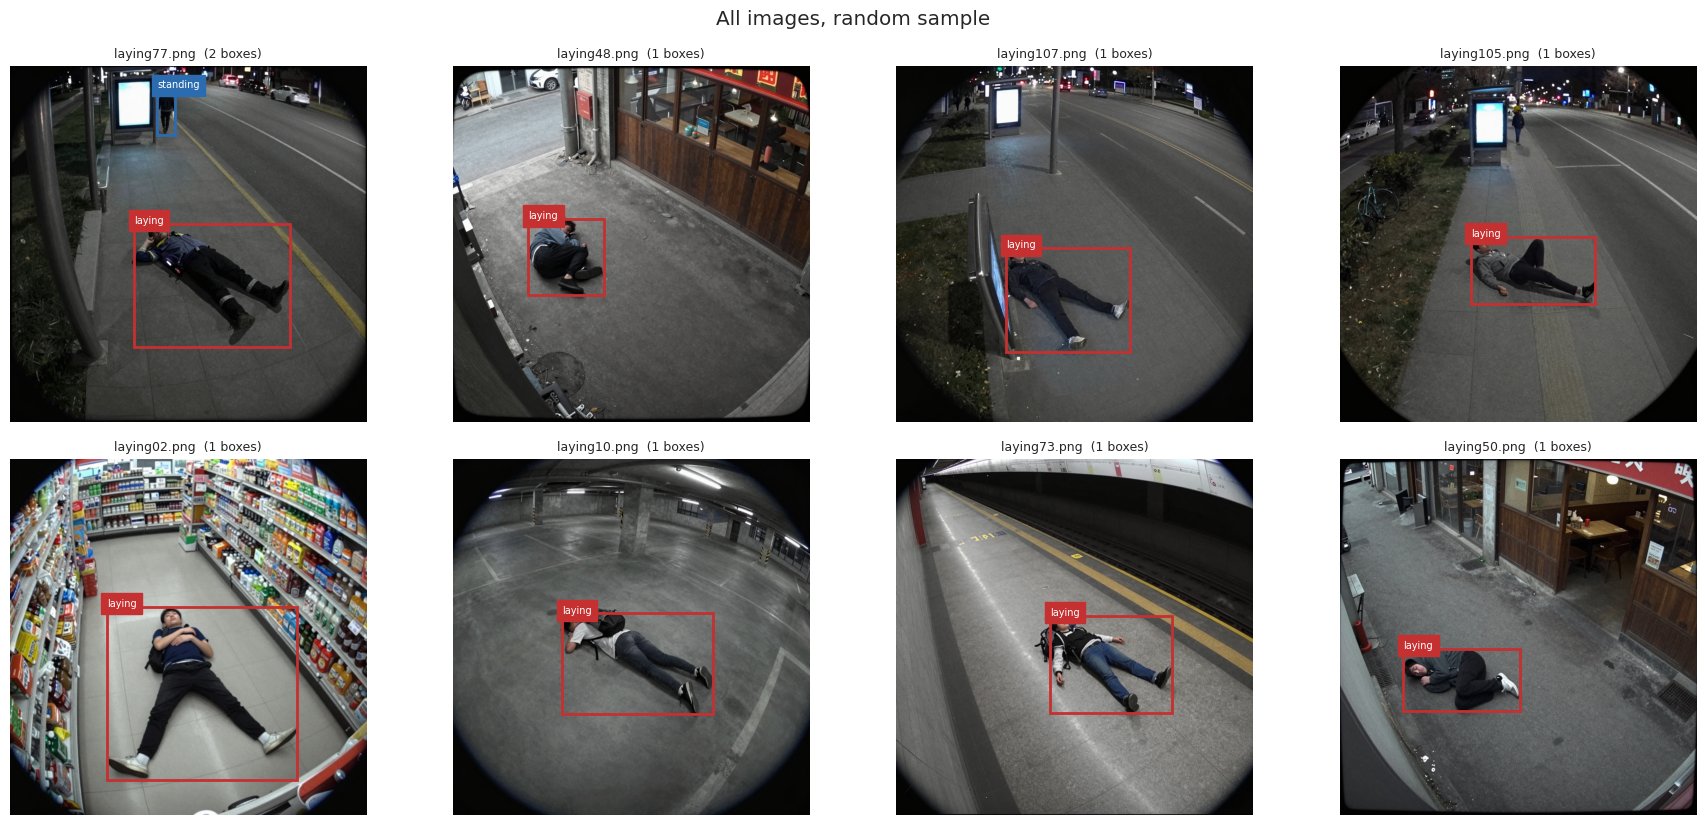

Saved figure: /content/drive/MyDrive/SAMS/results/vision/accident/preview_all.png


In [ ]:
all_staged = []
for record in STAGED:
    all_staged.append(record["image"])
preview_images(all_staged, "All images, random sample", "preview_all")

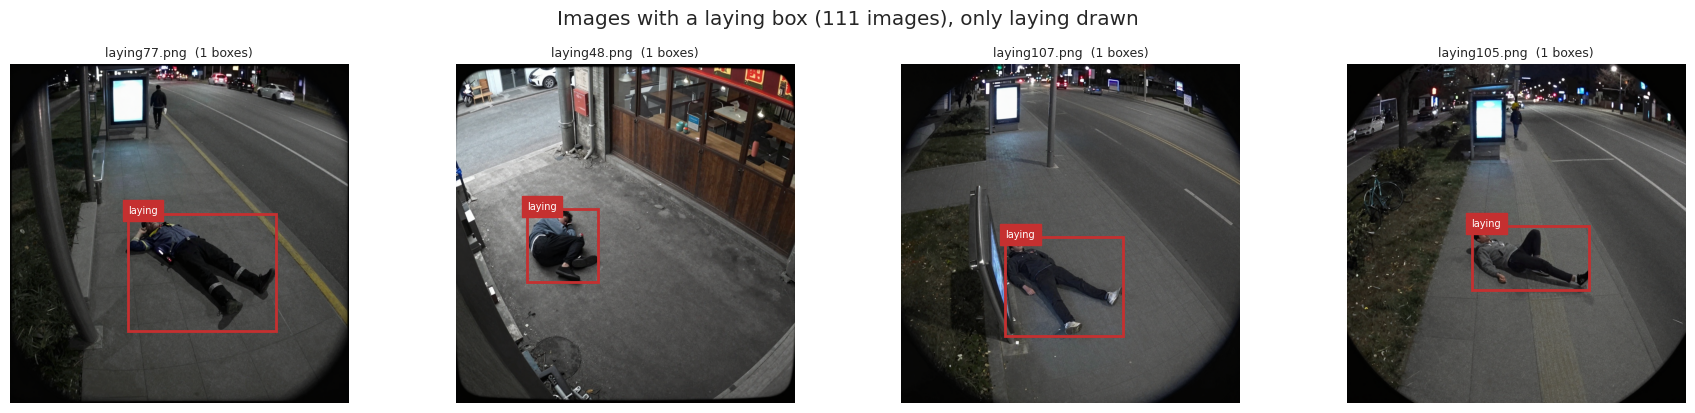

Saved figure: /content/drive/MyDrive/SAMS/results/vision/accident/preview_class_laying.png


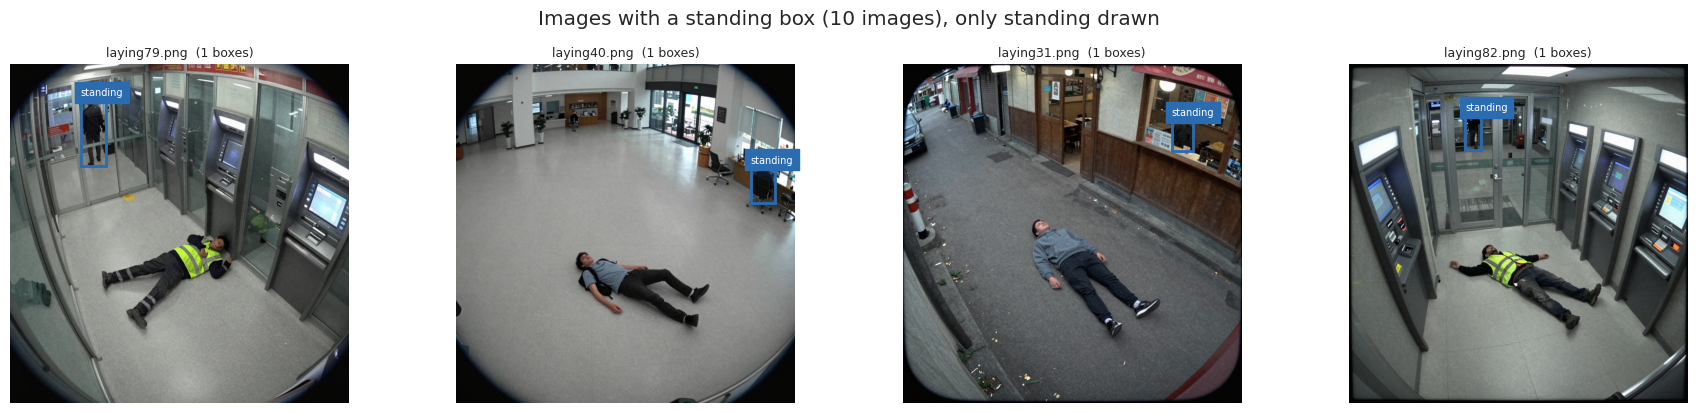

Saved figure: /content/drive/MyDrive/SAMS/results/vision/accident/preview_class_standing.png


In [ ]:
for class_id, class_name in CLASS_NAMES.items():
    with_class = []
    for record in STAGED:
        for row in read_labels(label_path_for(record["image"])):
            if row[0] == class_id:
                with_class.append(record["image"])
                break
    preview_images(
        with_class,
        f"Images with a {class_name} box ({len(with_class)} images), only {class_name} drawn",
        f"preview_class_{class_name}",
        columns=4,
        rows=1,
        only_class=class_id,
    )

## 3. One table of every image, and stratified train/val/test splits

The published YAML points train and val at the same folder. This notebook builds its own splits so val and test are never seen during training.

Two DataFrames are built here and used by everything after this point:

- `manifest`: one row per image, with size, brightness, contrast, number of boxes, and a count column for each class.
- `boxes`: one row per box, with its class, position, size, and aspect ratio.

### How splits are built

- Stratified **70 / 15 / 15** train / val / test by whether the image contains at least one `laying` box (`has_laying`). Seed **42**.
- Val and test hold only original dataset images. They are never augmented.
- The same val and test lists are used for every experiment.

In [ ]:
from sklearn.model_selection import train_test_split

manifest_rows = []
box_rows = []
for record in STAGED:
    image_path = record["image"]
    with Image.open(image_path) as image:
        width, height = image.size
        small = image.convert("L").resize((64, 64))
    grey = np.asarray(small, dtype=np.float32)
    rows = read_labels(label_path_for(image_path))

    entry = {
        "image": str(image_path),
        "original": record["original"],
        "width": width,
        "height": height,
        "brightness": float(grey.mean()),
        "contrast": float(grey.std()),
        "boxes": len(rows),
    }
    for class_name in CLASS_NAMES.values():
        entry[class_name] = 0

    areas = []
    aspects = []
    centers_x = []
    centers_y = []
    for class_id, xc, yc, w, h in rows:
        class_name = CLASS_NAMES[class_id]
        entry[class_name] += 1
        box_w_px = w * width
        box_h_px = h * height
        aspect = box_w_px / max(box_h_px, 1e-6)
        areas.append(w * h)
        aspects.append(aspect)
        centers_x.append(xc)
        centers_y.append(yc)
        box_rows.append({
            "image": str(image_path),
            "class": class_name,
            "xc": xc,
            "yc": yc,
            "w": w,
            "h": h,
            "rel_area": w * h,
            "box_w_px": box_w_px,
            "box_h_px": box_h_px,
            "aspect": aspect,
            "size": size_bucket(w, h, width, height),
            "shape": shape_bucket(aspect),
        })

    if areas:
        entry["mean_box_area"] = float(np.mean(areas))
        entry["mean_aspect"] = float(np.mean(aspects))
        entry["mean_xc"] = float(np.mean(centers_x))
        entry["mean_yc"] = float(np.mean(centers_y))
    else:
        entry["mean_box_area"] = 0.0
        entry["mean_aspect"] = 0.0
        entry["mean_xc"] = 0.5
        entry["mean_yc"] = 0.5

    if entry["laying"] > 0 and entry["standing"] > 0:
        entry["image_type"] = "laying and standing"
    elif entry["laying"] > 0:
        entry["image_type"] = "laying only"
    elif entry["standing"] > 0:
        entry["image_type"] = "standing only"
    else:
        entry["image_type"] = "no person"
    manifest_rows.append(entry)

manifest = pd.DataFrame(manifest_rows)
boxes = pd.DataFrame(box_rows)
manifest["has_laying"] = manifest["laying"] > 0
display(manifest.head())
display(boxes.head())

,image,original,width,height,brightness,contrast,boxes,laying,standing,mean_box_area,mean_aspect,mean_xc,mean_yc,image_type,has_laying
0,/content/SAMS/datasets/vision/accident/merged/...,laying01.png,1024,1024,135.351807,38.445801,1,1,0,0.121863,1.778164,0.585099,0.532050,laying only,True
1,/content/SAMS/datasets/vision/accident/merged/...,laying02.png,1024,1024,121.159180,53.163185,1,1,0,0.260592,1.097649,0.539075,0.658637,laying only,True
2,/content/SAMS/datasets/vision/accident/merged/...,laying03.png,1024,1024,78.185303,32.098774,1,1,0,0.105655,1.769502,0.489547,0.538264,laying only,True
3,/content/SAMS/datasets/vision/accident/merged/...,laying04.png,1024,1024,145.454346,42.516975,1,1,0,0.107814,1.817137,0.549052,0.573779,laying only,True
4,/content/SAMS/datasets/vision/accident/merged/...,laying05.png,1024,1024,131.711426,34.309830,1,1,0,0.102528,1.813851,0.563548,0.563365,laying only,True


,image,class,xc,yc,w,h,rel_area,box_w_px,box_h_px,aspect,size,shape
0,/content/SAMS/datasets/vision/accident/merged/...,laying,0.585099,0.532050,0.465502,0.261788,0.121863,476.674048,268.070912,1.778164,large,wide
1,/content/SAMS/datasets/vision/accident/merged/...,laying,0.539075,0.658637,0.534826,0.487247,0.260592,547.661824,498.940928,1.097649,large,square
2,/content/SAMS/datasets/vision/accident/merged/...,laying,0.489547,0.538264,0.432385,0.244354,0.105655,442.762240,250.218496,1.769502,large,wide
3,/content/SAMS/datasets/vision/accident/merged/...,laying,0.549052,0.573779,0.442620,0.243581,0.107814,453.242880,249.426944,1.817137,large,wide
4,/content/SAMS/datasets/vision/accident/merged/...,laying,0.563548,0.563365,0.431243,0.237750,0.102528,441.592832,243.456000,1.813851,large,wide


In [ ]:
label = manifest["has_laying"].astype(int).to_numpy()
indices = np.arange(len(manifest))
train_idx, temp_idx = train_test_split(
    indices,
    test_size=VAL_FRACTION + TEST_FRACTION,
    stratify=label,
    random_state=SEED,
)
temp_label = label[temp_idx]
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=TEST_FRACTION / (VAL_FRACTION + TEST_FRACTION),
    stratify=temp_label,
    random_state=SEED,
)

manifest["split"] = "unused"
manifest.loc[train_idx, "split"] = "train"
manifest.loc[val_idx, "split"] = "val"
manifest.loc[test_idx, "split"] = "test"
boxes["split"] = boxes["image"].map(dict(zip(manifest["image"], manifest["split"])))

split_rows = []
for split_name in ["train", "val", "test"]:
    subset = manifest[manifest["split"] == split_name]
    split_rows.append({
        "split": split_name,
        "images": len(subset),
        "share of images": len(subset) / len(manifest),
        "images with laying": int(subset["has_laying"].sum()),
        "laying boxes": int(subset["laying"].sum()),
        "standing boxes": int(subset["standing"].sum()),
    })
save_table(pd.DataFrame(split_rows).set_index("split").round(3), "split_summary")

,images,share of images,images with laying,laying boxes,standing boxes
split,,,,,
train,77,0.694,77,77,9
val,17,0.153,17,17,1
test,17,0.153,17,17,0


In [ ]:
TRAIN_IMAGES = []
for image_path in manifest.loc[manifest["split"] == "train", "image"]:
    TRAIN_IMAGES.append(Path(image_path))
VAL_IMAGES = []
for image_path in manifest.loc[manifest["split"] == "val", "image"]:
    VAL_IMAGES.append(Path(image_path))
TEST_IMAGES = []
for image_path in manifest.loc[manifest["split"] == "test", "image"]:
    TEST_IMAGES.append(Path(image_path))

VAL_LIST = write_list("val", VAL_IMAGES)
TEST_LIST = write_list("test", TEST_IMAGES)

list_rows = [
    {"list": "train", "images": len(TRAIN_IMAGES), "file": "(built in section 6)"},
    {"list": "val", "images": len(VAL_IMAGES), "file": str(VAL_LIST)},
    {"list": "test", "images": len(TEST_IMAGES), "file": str(TEST_LIST)},
]
display(pd.DataFrame(list_rows).set_index("list"))

,images,file
list,,
train,77,(built in section 6)
val,17,/content/SAMS/datasets/vision/accident/merged/...
test,17,/content/SAMS/datasets/vision/accident/merged/...


The table below checks that each class has enough real boxes to be scored. A class marked `False` will have a noisy score. With about ten `standing` boxes in the whole dataset, `standing` is expected to be `False`: its val and test scores should be read as a rough sign, not a measurement.

In [ ]:
eval_table = pd.DataFrame(index=list(CLASS_NAMES.values()))
eval_table.index.name = "class"
for split_name in ["train", "val", "test"]:
    subset = manifest[manifest["split"] == split_name]
    column = []
    for class_name in CLASS_NAMES.values():
        column.append(int(subset[class_name].sum()))
    eval_table[split_name] = column
eval_table["val has enough"] = eval_table["val"] >= MIN_EVAL_BOXES
eval_table["test has enough"] = eval_table["test"] >= MIN_EVAL_BOXES
save_table(eval_table, "eval_split_sufficiency")

,train,val,test,val has enough,test has enough
class,,,,,
laying,77,17,17,True,True
standing,9,1,0,False,False


### Preview of val and test

Eight random images from each split with their labels. Val and test are the images every experiment is scored on.

In [ ]:
preview_images(TRAIN_IMAGES, "Train split, real images only", "preview_train")
preview_images(VAL_IMAGES, "Val split, real images only", "preview_val")
preview_images(TEST_IMAGES, "Test split, real images only", "preview_test")

## 4. Exploratory data analysis

The EDA answers six questions before any training:

1. How much data is there per split and class?
2. How many people are in each image?
3. How big are the people at the training image size?
4. How different are lying and standing people in shape? A fallen person is usually wider than tall, but a fall towards the camera can look tall.
5. Where in the frame do people sit, and do the images vary in resolution and brightness?
6. Which classes appear together? Balancing copies whole images, so this decides what a copy adds.

The EDA uses every image (train, val, and test), unless a cell says otherwise.

### 4.1 Images and boxes per split

The left chart counts images, the right chart counts boxes per class. Expect a strong imbalance: almost every image has a `laying` box, and `standing` is rare in every split.

split,train,val,test
class,,,
laying,77,17,17
standing,9,1,0


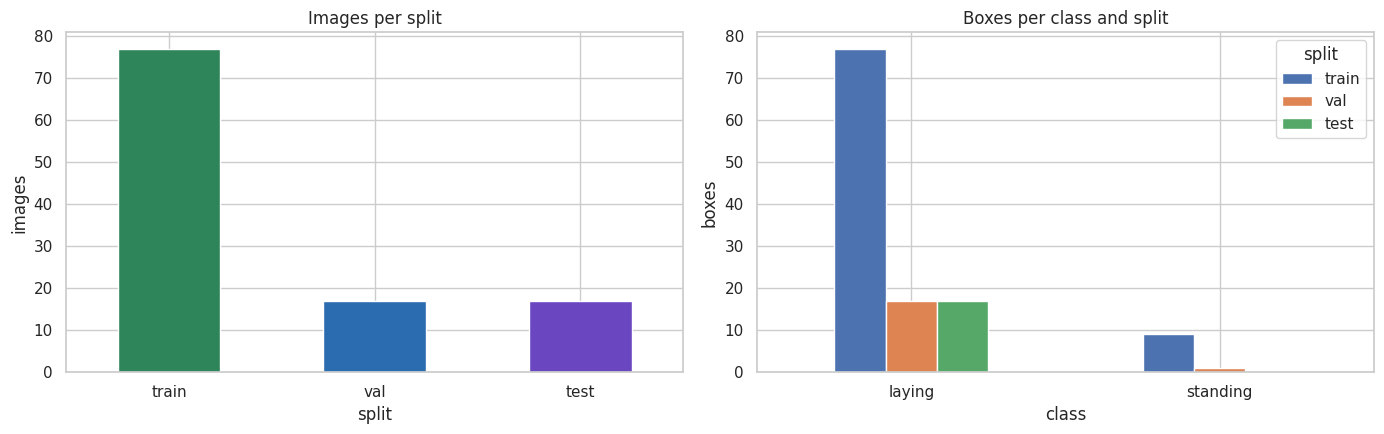

Saved figure: /content/drive/MyDrive/SAMS/results/vision/accident/eda_images_and_boxes_per_split.png


In [ ]:
class_order = list(CLASS_NAMES.values())

split_class = pd.crosstab(boxes["class"], boxes["split"])
split_class = split_class.reindex(index=class_order, columns=["train", "val", "test"], fill_value=0)
save_table(split_class, "eda_boxes_per_class_split")

images_per_split = manifest["split"].value_counts().reindex(["train", "val", "test"], fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
images_per_split.plot(kind="bar", ax=axes[0], color=["#2f855a", "#2b6cb0", "#6b46c1"])
axes[0].set_title("Images per split")
axes[0].set_ylabel("images")
axes[0].tick_params(axis="x", rotation=0)
split_class.plot(kind="bar", ax=axes[1])
axes[1].set_title("Boxes per class and split")
axes[1].set_ylabel("boxes")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
save_figure(fig, "eda_images_and_boxes_per_split")

### 4.2 Boxes per image

How many labelled people each image holds. Crowded images are harder, and they also matter for balancing: copying an image copies every person in it.

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,17.0,1.00,0.00,1.0,1.0,1.0,1.0,1.0
train,77.0,1.12,0.32,1.0,1.0,1.0,1.0,2.0
val,17.0,1.06,0.24,1.0,1.0,1.0,1.0,2.0


split,train,val,test
boxes,,,
1,68,16,17
2,9,1,0


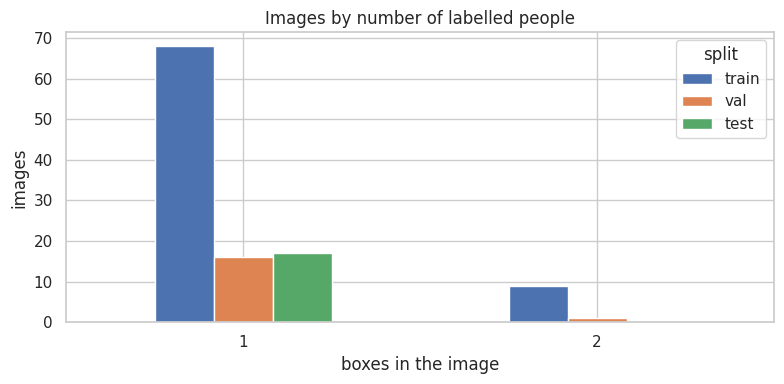

Saved figure: /content/drive/MyDrive/SAMS/results/vision/accident/eda_boxes_per_image.png


In [ ]:
per_image = manifest.groupby("split")["boxes"].describe()
save_table(per_image.round(2), "eda_boxes_per_image")

box_count_table = pd.crosstab(manifest["boxes"], manifest["split"])
box_count_table = box_count_table.reindex(columns=["train", "val", "test"], fill_value=0)
save_table(box_count_table, "eda_boxes_per_image_counts")

fig, ax = plt.subplots(figsize=(8, 4))
box_count_table.plot(kind="bar", ax=ax)
ax.set_title("Images by number of labelled people")
ax.set_xlabel("boxes in the image")
ax.set_ylabel("images")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
save_figure(fig, "eda_boxes_per_image")

### 4.3 Box size

Box area is shown as a share of the image area, on a log scale. The size table uses the COCO convention after the image is resized to `IMGSZ_BASE` pixels for training: small is under 32 by 32 pixels, medium is under 96 by 96, large is anything bigger. Many small people would be a reason to expect a gain from the larger image size tested in section 10.

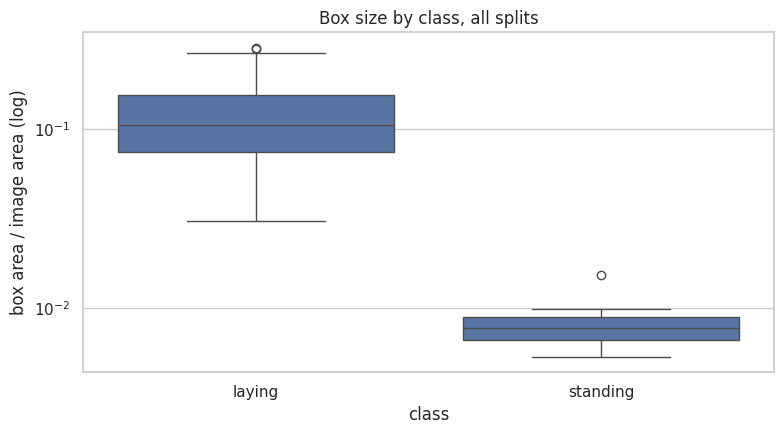

Saved figure: /content/drive/MyDrive/SAMS/results/vision/accident/eda_box_area_by_class.png


size,small,medium,large
class,,,
laying,0,0.0,100.0
standing,0,100.0,0.0


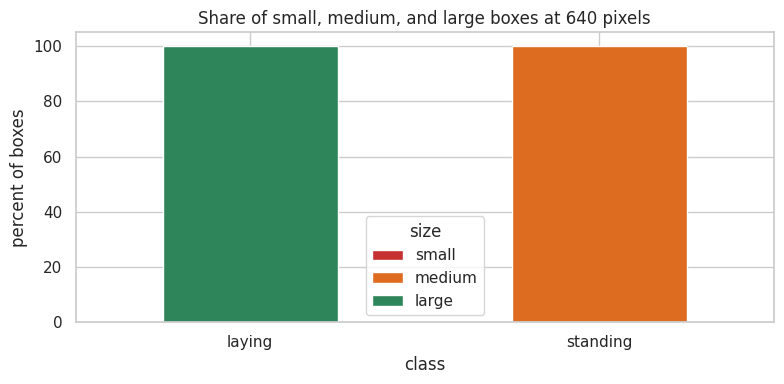

Saved figure: /content/drive/MyDrive/SAMS/results/vision/accident/eda_box_size_share.png


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=boxes, x="class", y="rel_area", order=class_order, showfliers=True, ax=ax)
ax.set_yscale("log")
ax.set_ylabel("box area / image area (log)")
ax.set_title("Box size by class, all splits")
plt.tight_layout()
save_figure(fig, "eda_box_area_by_class")

size_table = pd.crosstab(boxes["class"], boxes["size"], normalize="index") * 100
size_table = size_table.reindex(index=class_order, columns=["small", "medium", "large"], fill_value=0)
size_table = size_table.round(1)
save_table(size_table, "eda_box_size_share_percent")

fig, ax = plt.subplots(figsize=(8, 4))
size_table.plot(kind="bar", stacked=True, ax=ax, color=["#c53030", "#dd6b20", "#2f855a"])
ax.set_ylabel("percent of boxes")
ax.set_title(f"Share of small, medium, and large boxes at {IMGSZ_BASE} pixels")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
save_figure(fig, "eda_box_size_share")

### 4.4 Box shape: the most telling feature for a fall

Aspect ratio is box width divided by box height, in pixels. A standing person seen by a CCTV camera is clearly taller than wide (aspect well under 1). A person lying across the view is wider than tall. A person lying along the camera's line of sight is foreshortened and can look square or even tall, which is the hard case.

The left chart shows the aspect ratio per class on a log scale, the right chart box width against box height. The table below them asks how far a simple rule on aspect ratio alone would get: the cut that best separates the two classes, and its balanced accuracy. If that accuracy is close to 1, the detector mainly needs to box people well. If it is clearly below 1, the detector has to learn posture, not just shape.

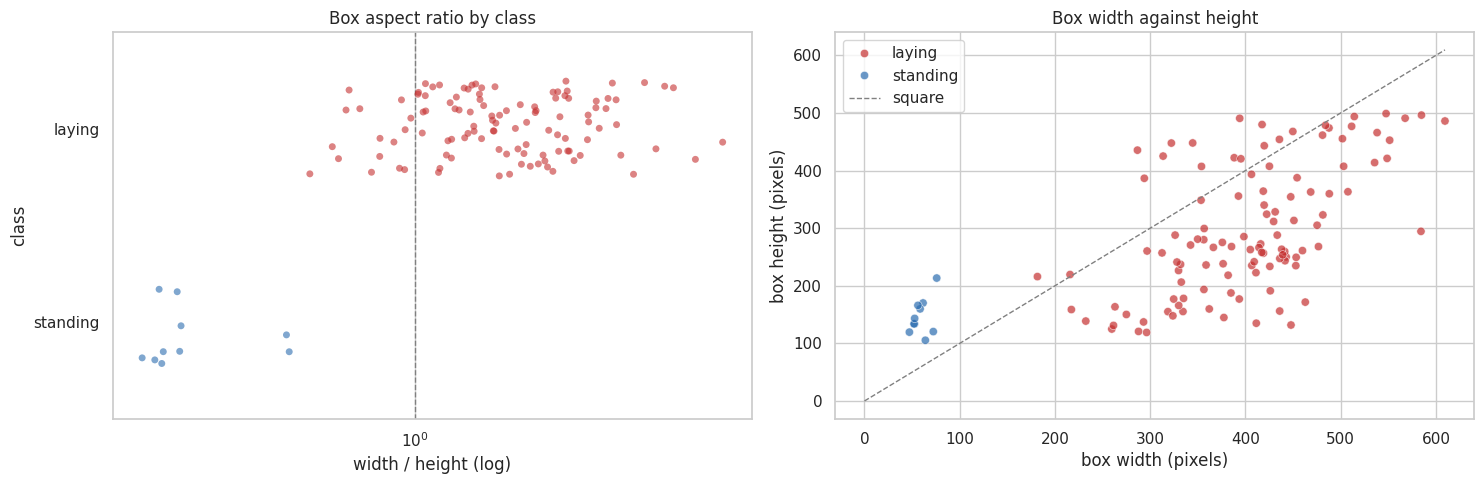

Saved figure: /content/drive/MyDrive/SAMS/results/vision/accident/eda_box_aspect.png


,count,min,25%,50%,75%,max,percent wider than tall
class,,,,,,,
laying,111.0,0.66,1.14,1.40,1.80,3.40,86.49
standing,10.0,0.34,0.36,0.38,0.39,0.61,0.00


shape,tall,square,wide
class,,,
laying,5,34,72
standing,10,0,0


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.stripplot(data=boxes, x="aspect", y="class", order=class_order, hue="class", hue_order=class_order,
              palette=[CLASS_COLORS[0], CLASS_COLORS[1]], alpha=0.6, size=5, jitter=0.25, legend=False, ax=axes[0])
axes[0].set_xscale("log")
axes[0].axvline(1.0, color="grey", linestyle="--", linewidth=1)
axes[0].set_xlabel("width / height (log)")
axes[0].set_title("Box aspect ratio by class")

sns.scatterplot(data=boxes, x="box_w_px", y="box_h_px", hue="class", hue_order=class_order,
                palette=[CLASS_COLORS[0], CLASS_COLORS[1]], alpha=0.7, ax=axes[1])
largest_side = float(max(boxes["box_w_px"].max(), boxes["box_h_px"].max()))
axes[1].plot([0, largest_side], [0, largest_side], color="grey", linestyle="--", linewidth=1, label="square")
axes[1].set_xlabel("box width (pixels)")
axes[1].set_ylabel("box height (pixels)")
axes[1].set_title("Box width against height")
axes[1].legend()
plt.tight_layout()
save_figure(fig, "eda_box_aspect")

aspect_table = boxes.groupby("class")["aspect"].describe()[["count", "min", "25%", "50%", "75%", "max"]]
wider_share = []
for class_name in aspect_table.index:
    class_aspects = boxes.loc[boxes["class"] == class_name, "aspect"]
    wider_share.append(float((class_aspects > 1.0).mean() * 100))
aspect_table["percent wider than tall"] = wider_share
save_table(aspect_table.reindex(class_order).round(2), "eda_box_aspect_by_class")

shape_table = pd.crosstab(boxes["class"], boxes["shape"]).reindex(index=class_order, columns=["tall", "square", "wide"], fill_value=0)
save_table(shape_table, "eda_box_shape_counts")

In [ ]:
is_laying = (boxes["class"] == FALL_CLASS).to_numpy()

is_standing = ~is_laying
aspects = boxes["aspect"].to_numpy()

best_cut = float("nan")
best_accuracy = float("nan")
if is_laying.any() and is_standing.any():
    best_accuracy = 0.0
    for cut in np.unique(aspects):
        predicted_laying = aspects >= cut
        laying_recall = float(np.mean(predicted_laying[is_laying]))
        standing_recall = float(np.mean(~predicted_laying[is_standing]))
        balanced_accuracy = (laying_recall + standing_recall) / 2
        if balanced_accuracy > best_accuracy:
            best_accuracy = balanced_accuracy
            best_cut = float(cut)

laying_below_cut = int(np.sum(is_laying & (aspects < best_cut)))
rule_table = pd.DataFrame([
    {"item": "best aspect cut (laying if width / height is at least this)", "value": round(best_cut, 3)},
    {"item": "balanced accuracy of that rule", "value": round(best_accuracy, 3)},
    {"item": "laying boxes below the cut (missed by the rule)", "value": laying_below_cut},
    {"item": "laying boxes in total", "value": int(is_laying.sum())},
]).set_index("item")
save_table(rule_table, "eda_aspect_rule")

,value
item,
best aspect cut (laying if width / height is at least this),0.658
balanced accuracy of that rule,1.000
laying boxes below the cut (missed by the rule),0.000
laying boxes in total,111.000


### 4.5 Where people sit in the image

Each panel is a map of box centers, with the top of the image at the top. If people always sit in the same part of the frame, the model may learn the position instead of the person, and a SAMS camera with a different view would suffer.

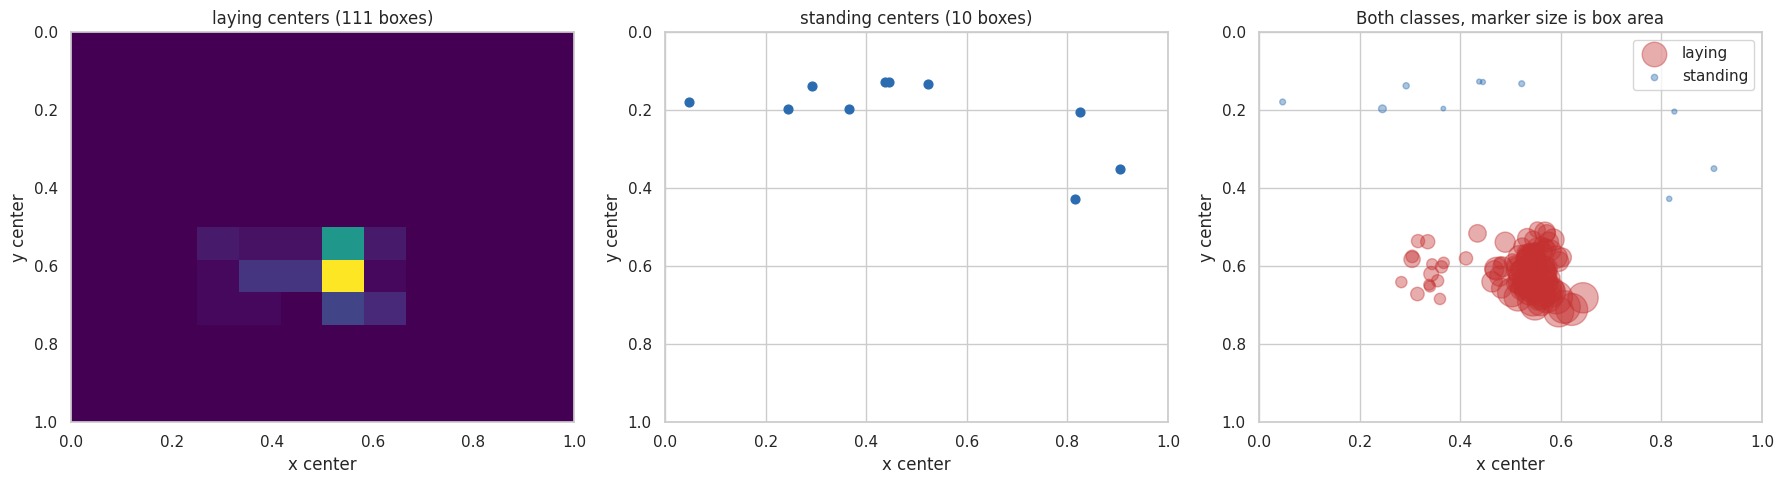

Saved figure: /content/drive/MyDrive/SAMS/results/vision/accident/eda_box_center_heatmaps.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
laying_boxes = boxes[boxes["class"] == "laying"]
standing_boxes = boxes[boxes["class"] == "standing"]

axes[0].hist2d(laying_boxes["xc"], laying_boxes["yc"], bins=12, range=[[0, 1], [0, 1]], cmap="viridis")
axes[0].set_title(f"laying centers ({len(laying_boxes)} boxes)")

axes[1].scatter(standing_boxes["xc"], standing_boxes["yc"], color=CLASS_COLORS[1], s=40)
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].set_title(f"standing centers ({len(standing_boxes)} boxes)")

for class_id, class_name in CLASS_NAMES.items():
    class_boxes = boxes[boxes["class"] == class_name]
    axes[2].scatter(class_boxes["xc"], class_boxes["yc"], s=class_boxes["rel_area"] * 2000,
                    color=CLASS_COLORS[class_id], alpha=0.4, label=class_name)
axes[2].set_xlim(0, 1)
axes[2].set_ylim(0, 1)
axes[2].set_title("Both classes, marker size is box area")
axes[2].legend()

for ax in axes:
    ax.invert_yaxis()
    ax.set_xlabel("x center")
    ax.set_ylabel("y center")
plt.tight_layout()
save_figure(fig, "eda_box_center_heatmaps")

### 4.6 Image resolution and brightness

Synthetic renders often share one resolution and one lighting setup. Real SAMS cameras do not. A narrow range here means the robustness test in section 10 (dark, blurred, compressed, low-resolution images) is the main evidence of how the model will behave on real footage.

,images,median_width,median_height,min_width,max_width,mean_brightness,std_brightness,mean_contrast
split,,,,,,,,
test,17,1024.0,1024.0,1024,1024,107.4,20.3,43.8
train,77,1024.0,1024.0,1024,1024,103.0,22.2,41.5
val,17,1024.0,1024.0,1024,1024,97.1,23.3,41.4


,,images
width,height,
1024,1024,111


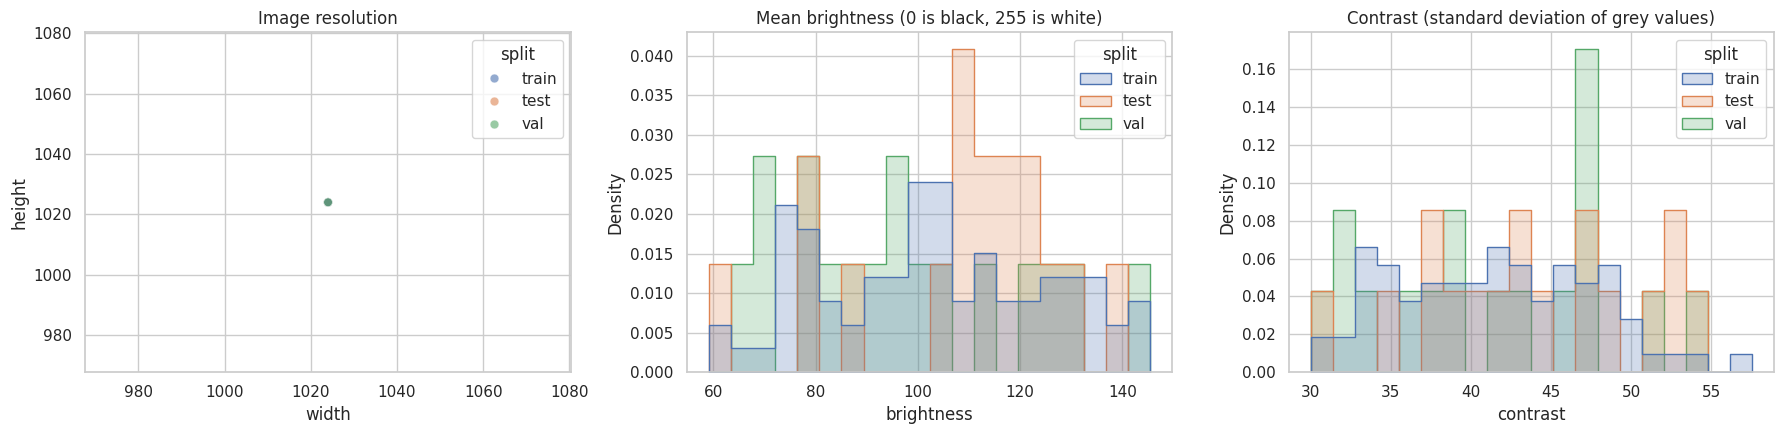

Saved figure: /content/drive/MyDrive/SAMS/results/vision/accident/eda_resolution_brightness.png


In [ ]:
look_table = manifest.groupby("split").agg(
    images=("image", "count"),
    median_width=("width", "median"),
    median_height=("height", "median"),
    min_width=("width", "min"),
    max_width=("width", "max"),
    mean_brightness=("brightness", "mean"),
    std_brightness=("brightness", "std"),
    mean_contrast=("contrast", "mean"),
)
save_table(look_table.round(1), "eda_resolution_brightness")

resolution_counts = manifest.groupby(["width", "height"]).size().reset_index(name="images")
save_table(resolution_counts.set_index(["width", "height"]), "eda_resolutions")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.scatterplot(data=manifest, x="width", y="height", hue="split", alpha=0.6, s=40, ax=axes[0])
axes[0].set_title("Image resolution")
sns.histplot(data=manifest, x="brightness", hue="split", bins=20, stat="density", common_norm=False,
             element="step", ax=axes[1])
axes[1].set_title("Mean brightness (0 is black, 255 is white)")
sns.histplot(data=manifest, x="contrast", hue="split", bins=20, stat="density", common_norm=False,
             element="step", ax=axes[2])
axes[2].set_title("Contrast (standard deviation of grey values)")
plt.tight_layout()
save_figure(fig, "eda_resolution_brightness")

### 4.7 Which classes appear together

The first table counts images by what they contain. The heatmap shows, for images with the row class, the percent that also contain the column class. If every `standing` image also has a `laying` person, copying `standing` images to balance them will raise `laying` too, and the model never sees a scene with only upright people.

split,train,val,test
image_type,,,
laying only,68,16,17
laying and standing,9,1,0
standing only,0,0,0
no person,0,0,0


,laying,standing
laying,100.0,9.0
standing,100.0,100.0


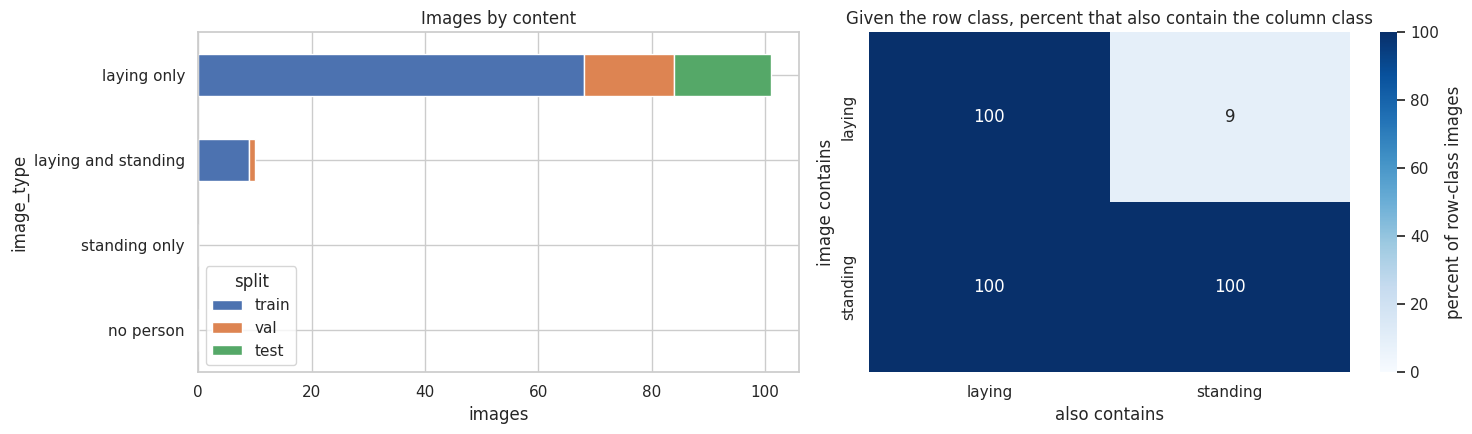

Saved figure: /content/drive/MyDrive/SAMS/results/vision/accident/eda_class_cooccurrence.png


In [ ]:
type_order = ["laying only", "laying and standing", "standing only", "no person"]
type_table = pd.crosstab(manifest["image_type"], manifest["split"])
type_table = type_table.reindex(index=type_order, columns=["train", "val", "test"], fill_value=0)
save_table(type_table, "eda_image_types")

presence = (manifest[class_order] > 0).astype(int)
together = presence.T.dot(presence)
images_with_class = np.diag(together).astype(float)
images_with_class[images_with_class == 0] = np.nan
conditional = together.div(images_with_class, axis=0) * 100
save_table(conditional.round(1), "eda_class_cooccurrence_percent")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
type_table.plot(kind="barh", stacked=True, ax=axes[0])
axes[0].set_title("Images by content")
axes[0].set_xlabel("images")
axes[0].invert_yaxis()
sns.heatmap(conditional, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, ax=axes[1],
            cbar_kws={"label": "percent of row-class images"})
axes[1].set_title("Given the row class, percent that also contain the column class")
axes[1].set_xlabel("also contains")
axes[1].set_ylabel("image contains")
plt.tight_layout()
save_figure(fig, "eda_class_cooccurrence")

### 4.8 Person crops, sorted by shape

The top row shows eight `laying` crops spread evenly from the tallest box to the widest. The bottom row shows `standing` crops. The tall end of the `laying` row is where a shape rule fails and the detector has to recognise the pose. Check also that the crops look like people and not like furniture, which would point to label errors.

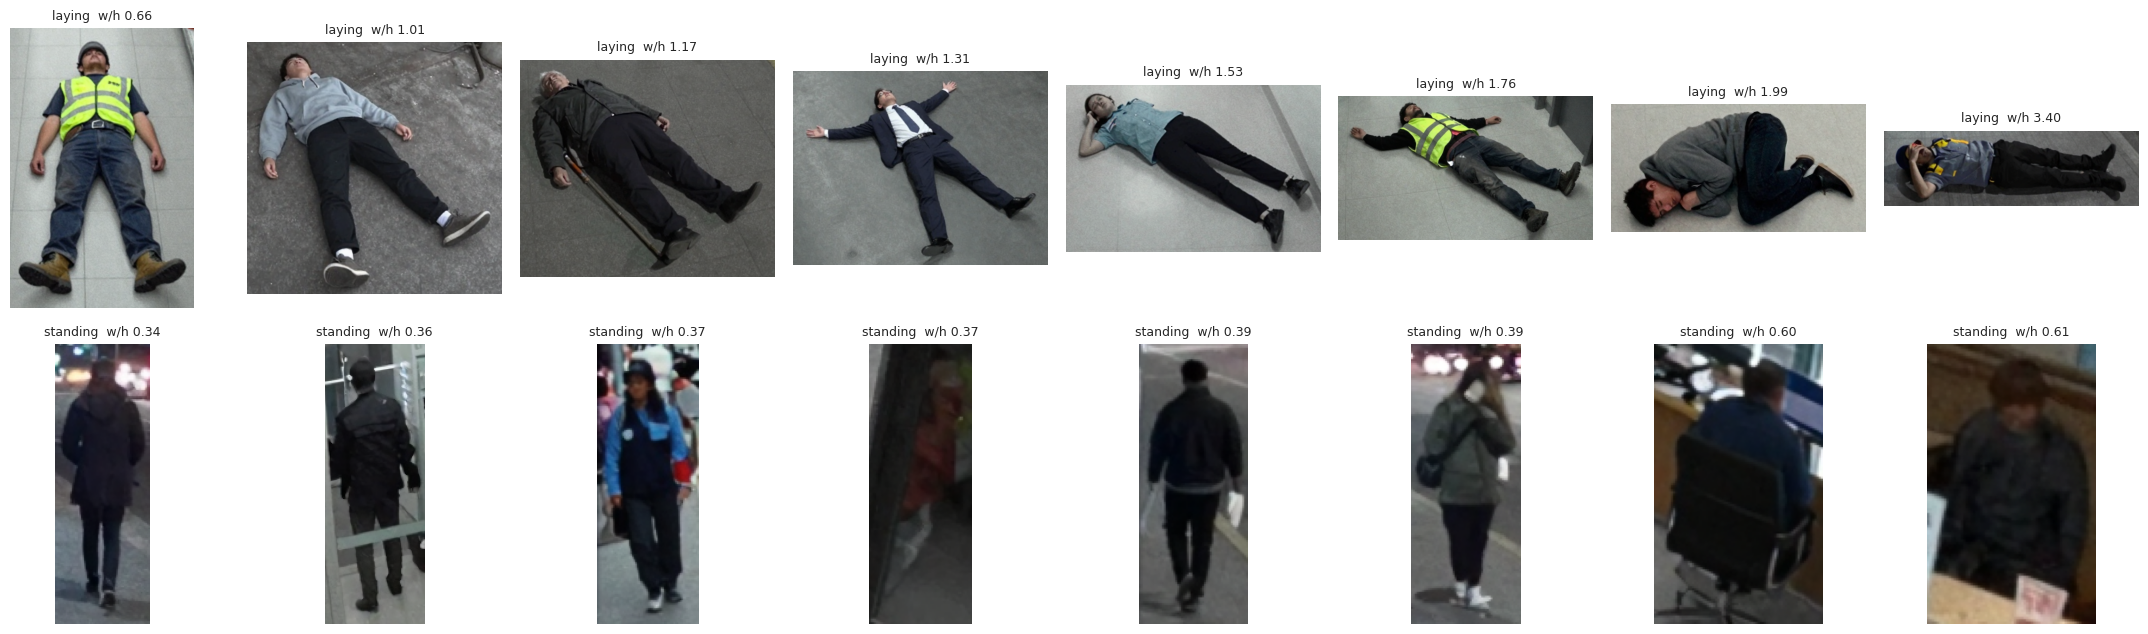

Saved figure: /content/drive/MyDrive/SAMS/results/vision/accident/eda_crops_by_shape.png


In [ ]:
def evenly_spread(frame, count):
    """Pick count rows spread evenly over a frame that is already sorted."""
    if len(frame) <= count:
        return frame
    positions = np.linspace(0, len(frame) - 1, count).round().astype(int)
    return frame.iloc[positions]


fig, axes = plt.subplots(2, 8, figsize=(22, 6.5))
for ax in axes.flatten():
    ax.axis("off")
for row_number, class_name in enumerate(class_order):
    class_boxes = boxes[boxes["class"] == class_name].sort_values("aspect")
    chosen_boxes = evenly_spread(class_boxes, 8)
    column_number = 0
    for _, box_row in chosen_boxes.iterrows():
        with Image.open(box_row["image"]) as image:
            crop = crop_box(image.convert("RGB"), box_row["xc"], box_row["yc"], box_row["w"], box_row["h"])
        ax = axes[row_number, column_number]
        ax.imshow(crop)
        ax.set_title(f"{class_name}  w/h {box_row['aspect']:.2f}", fontsize=9)
        column_number += 1
plt.tight_layout()
save_figure(fig, "eda_crops_by_shape")

### 4.9 What the EDA means for balancing

This table is the input to section 6. `gap to target` is how many training boxes each class is missing. With one source, there are no other real images to pull in, so a gap that is left after the real-image step has to be filled with augmented copies, capped at `MAX_COPIES_PER_IMAGE` per photo.

In [ ]:
train_images = manifest[manifest["split"] == "train"]
train_boxes = boxes[boxes["split"] == "train"]

gap_rows = []
for class_name in BALANCE_CLASSES:
    total = int(train_images[class_name].sum())
    images_with = int((train_images[class_name] > 0).sum())
    gap_rows.append({
        "class": class_name,
        "train boxes": total,
        "images containing it": images_with,
        "target": TARGET_BOXES_PER_CLASS,
        "gap to target": max(0, TARGET_BOXES_PER_CLASS - total),
        "most boxes reachable with copies": total + images_with * MAX_COPIES_PER_IMAGE,
    })
save_table(pd.DataFrame(gap_rows).set_index("class"), "eda_balance_gap")

,train boxes,images containing it,target,gap to target,most boxes reachable with copies
class,,,,,
laying,77,77,80,3,539
standing,9,9,80,71,63


## 5. PCA

PCA (principal component analysis) turns many correlated numbers into a few new axes, ordered by how much of the variation they explain. Plotting the first two axes shows the structure of the data in one picture.

Two PCAs are run:

1. **Image level**: one row per image, built from its class counts, box statistics, resolution, brightness, and contrast. This shows whether val and test cover the same kinds of images as training, and whether images with a standing person stand apart.
2. **Object level**: one row per person crop, built from a pretrained ResNet-18 image embedding. This shows whether lying and standing people look different enough to be told apart before any detector training.

### 5.1 Image-level PCA

Each feature is standardised (mean 0, standard deviation 1) first, so large numbers such as image width do not dominate small ones such as class counts. A feature that never changes (for example, one fixed resolution) adds nothing and gets a loading of 0.

,explained variance %,cumulative %
component,,
PC1,35.6,35.6
PC2,23.3,58.8
PC3,19.7,78.6
PC4,10.6,89.2
PC5,5.0,94.2


,PC1,PC2
standing,0.574,0.087
boxes,0.574,0.087
mean_yc,-0.507,0.192
mean_aspect,-0.191,-0.560
mean_box_area,-0.182,0.629
brightness,-0.122,-0.120
contrast,-0.019,0.106
mean_xc,-0.017,0.462
width,0.000,-0.000
laying,-0.000,0.000


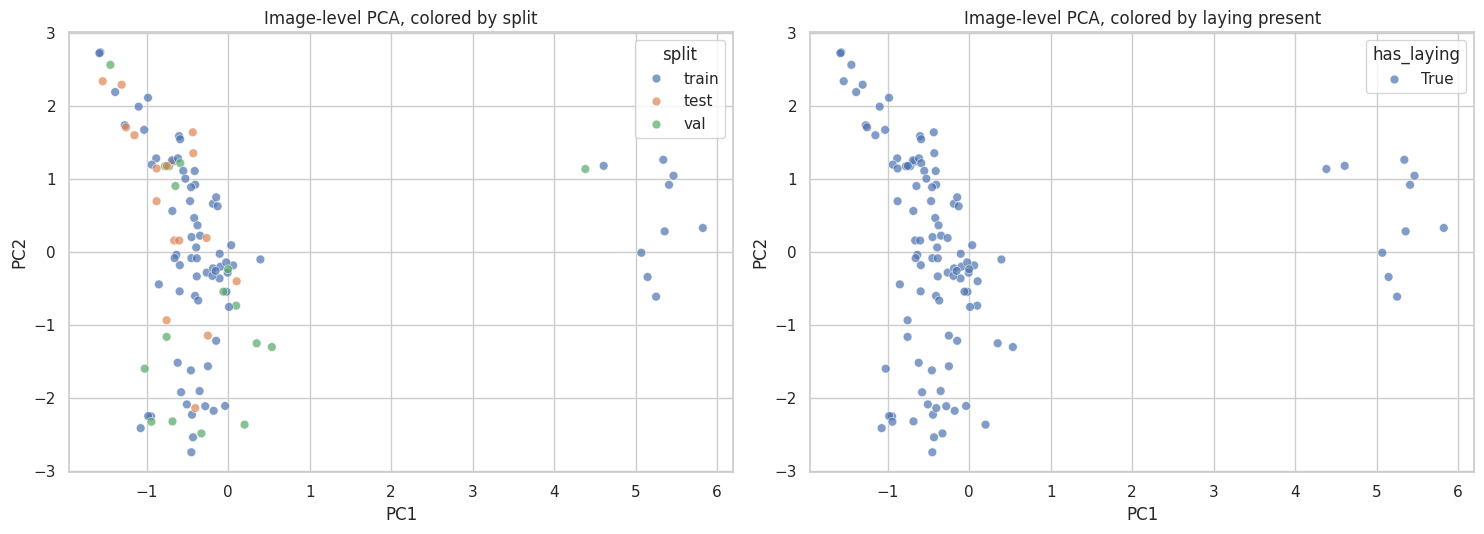

Saved figure: /content/drive/MyDrive/SAMS/results/vision/accident/pca_image_level.png


In [ ]:
IMAGE_FEATURES = list(CLASS_NAMES.values()) + [
    "boxes", "width", "height", "brightness", "contrast", "mean_box_area", "mean_aspect", "mean_xc", "mean_yc",
]

pca_data = manifest.copy()
feature_matrix = pca_data[IMAGE_FEATURES].to_numpy(dtype=float)
scaled_features = StandardScaler().fit_transform(feature_matrix)

component_total = min(5, len(IMAGE_FEATURES), len(pca_data))
image_pca = PCA(n_components=component_total, random_state=SEED)
image_components = image_pca.fit_transform(scaled_features)
pca_data["PC1"] = image_components[:, 0]
pca_data["PC2"] = image_components[:, 1]

variance_rows = []
cumulative = 0.0
for index, ratio in enumerate(image_pca.explained_variance_ratio_):
    cumulative += ratio
    variance_rows.append({"component": f"PC{index + 1}", "explained variance %": ratio * 100, "cumulative %": cumulative * 100})
save_table(pd.DataFrame(variance_rows).set_index("component").round(1), "pca_image_explained_variance")

loadings = pd.DataFrame(image_pca.components_[:2].T, index=IMAGE_FEATURES, columns=["PC1", "PC2"])
loadings["abs PC1"] = loadings["PC1"].abs()
loadings = loadings.sort_values("abs PC1", ascending=False).drop(columns="abs PC1")
save_table(loadings.round(3), "pca_image_loadings")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.scatterplot(data=pca_data, x="PC1", y="PC2", hue="split", alpha=0.7, s=40, ax=axes[0])
axes[0].set_title("Image-level PCA, colored by split")
sns.scatterplot(data=pca_data, x="PC1", y="PC2", hue="has_laying", alpha=0.7, s=40, ax=axes[1])
axes[1].set_title("Image-level PCA, colored by laying present")
plt.tight_layout()
save_figure(fig, "pca_image_level")

How to read it: the loadings table says what each axis means (for example, PC1 driven by `mean_aspect` and `standing` means the main variation is posture). If val or test points sit where there are no training points, those images are unlike anything in training and will score lower.

### 5.2 Object-level PCA of person crops

Every person box is cropped with `CROP_PADDING` margin, from all splits, because `standing` has too few boxes in the train alone. This is a description of the data, and nothing here is used to choose a model, so using val and test crops does not leak into training. Each crop goes through ResNet-18 pretrained on ImageNet, which gives a 512-number description of what the crop looks like.

In [ ]:
resnet_weights = torchvision.models.ResNet18_Weights.DEFAULT
backbone = torchvision.models.resnet18(weights=resnet_weights)
backbone.fc = torch.nn.Identity()
backbone = backbone.eval().to(TORCH_DEVICE)
preprocess = resnet_weights.transforms()

crop_table = boxes[(boxes["box_w_px"] >= 16) & (boxes["box_h_px"] >= 16)].reset_index(drop=True)

embedding_parts = []
with torch.no_grad():
    for start in range(0, len(crop_table), 32):
        chunk = crop_table.iloc[start:start + 32]
        tensors = []
        for _, row in chunk.iterrows():
            with Image.open(row["image"]) as image:
                crop = crop_box(image.convert("RGB"), row["xc"], row["yc"], row["w"], row["h"])
            tensors.append(preprocess(crop))
        batch = torch.stack(tensors).to(TORCH_DEVICE)
        embedding_parts.append(backbone(batch).cpu().numpy())
crop_embeddings = np.concatenate(embedding_parts)

del backbone
gc.collect()
if HAS_GPU:
    torch.cuda.empty_cache()

crop_counts = crop_table["class"].value_counts().reindex(class_order, fill_value=0)
display(crop_counts.to_frame("crops embedded"))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 240MB/s]


,crops embedded
class,
laying,111
standing,10


The scatter plots show the crops on the first two components, colored by class and by split.

The separability table goes one step further. A logistic regression is trained with stratified cross-validation to tell `laying` crops from `standing` crops, with two kinds of input:

- the ResNet-18 embedding, reduced to its first components (the scaling and PCA are fitted inside each fold, so the held-out fold is never seen),
- only the box geometry: log aspect ratio and log relative area.

Balanced accuracy is used because the classes are very unequal: 0.5 means no better than guessing, 1.0 means perfect. If geometry alone scores as high as the embedding, shape carries most of the signal. The number of folds is limited by the number of `standing` crops, so the spread between folds is wide.

,explained variance %
component,
PC1,10.5
PC2,8.6


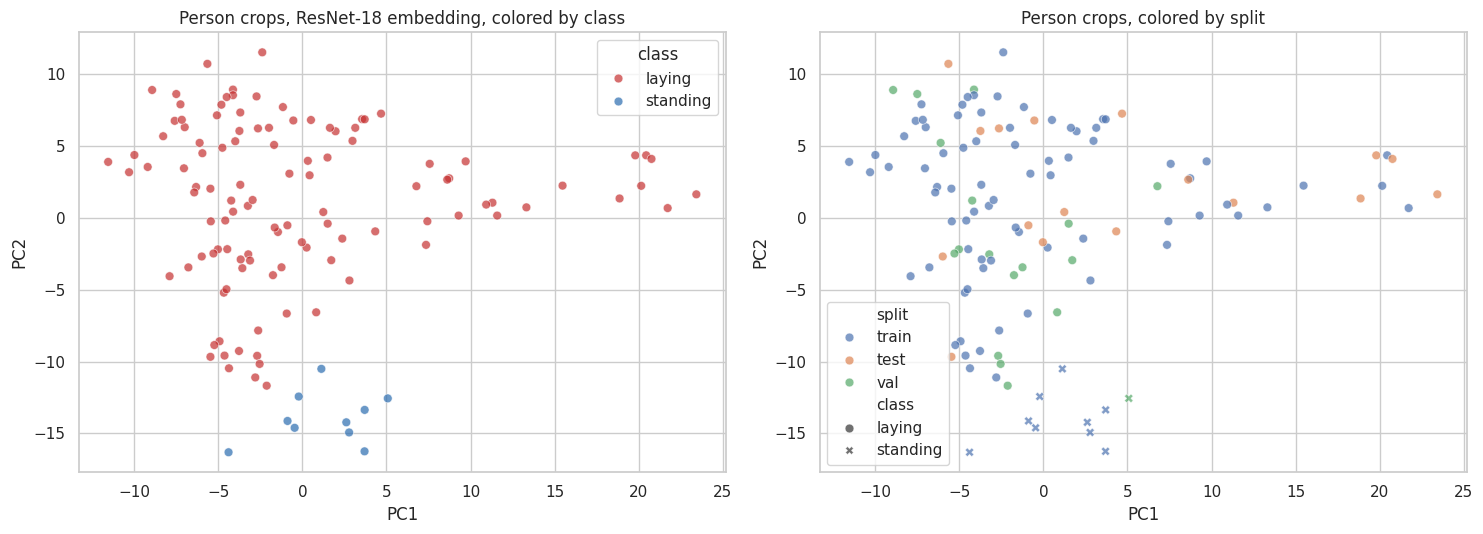

Saved figure: /content/drive/MyDrive/SAMS/results/vision/accident/pca_crops.png


,laying crops,standing crops,folds,balanced accuracy mean,balanced accuracy std
features,,,,,
ResNet-18 embedding,111,10,5,1.0,0.0
box geometry only,111,10,5,1.0,0.0


In [ ]:
crop_pca = PCA(n_components=2, random_state=SEED)
crop_2d = crop_pca.fit_transform(StandardScaler().fit_transform(crop_embeddings))
crop_table["PC1"] = crop_2d[:, 0]
crop_table["PC2"] = crop_2d[:, 1]

crop_variance = pd.DataFrame({
    "component": ["PC1", "PC2"],
    "explained variance %": [
        crop_pca.explained_variance_ratio_[0] * 100,
        crop_pca.explained_variance_ratio_[1] * 100,
    ],
}).set_index("component").round(1)
save_table(crop_variance, "pca_crop_explained_variance")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.scatterplot(data=crop_table, x="PC1", y="PC2", hue="class", hue_order=class_order,
                palette=[CLASS_COLORS[0], CLASS_COLORS[1]], alpha=0.7, s=40, ax=axes[0])
axes[0].set_title("Person crops, ResNet-18 embedding, colored by class")
sns.scatterplot(data=crop_table, x="PC1", y="PC2", hue="split", style="class", alpha=0.7, s=40, ax=axes[1])
axes[1].set_title("Person crops, colored by split")
plt.tight_layout()
save_figure(fig, "pca_crops")

target = (crop_table["class"] == "standing").astype(int).to_numpy()
smallest_class = int(min(target.sum(), len(target) - target.sum()))
fold_count = min(5, smallest_class)

geometry = np.column_stack([
    np.log(crop_table["aspect"].to_numpy()),
    np.log(crop_table["rel_area"].to_numpy()),
])
largest_held_out_fold = int(np.ceil(len(crop_table) / max(fold_count, 2)))
embedding_components = min(20, crop_embeddings.shape[1], len(crop_table) - largest_held_out_fold - 1)

separability_rows = []
feature_sets = [
    ("ResNet-18 embedding", crop_embeddings, embedding_components),
    ("box geometry only", geometry, 0),
]
for feature_name, features, components in feature_sets:
    row = {"features": feature_name, "laying crops": int((target == 0).sum()), "standing crops": int(target.sum()), "folds": fold_count}
    if fold_count < 2:
        row["balanced accuracy mean"] = np.nan
        row["balanced accuracy std"] = np.nan
        separability_rows.append(row)
        continue
    if components > 0:
        model = make_pipeline(StandardScaler(), PCA(n_components=components, random_state=SEED),
                              LogisticRegression(max_iter=2000, class_weight="balanced"))
    else:
        model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
    folds = StratifiedKFold(n_splits=fold_count, shuffle=True, random_state=SEED)
    scores = cross_val_score(model, features, target, cv=folds, scoring="balanced_accuracy")
    row["balanced accuracy mean"] = round(float(scores.mean()), 3)
    row["balanced accuracy std"] = round(float(scores.std()), 3)
    separability_rows.append(row)
save_table(pd.DataFrame(separability_rows).set_index("features"), "pca_crop_separability")

## 6. Build the training set

Every image in the train split is used. If `laying` boxes in train are below `TARGET_BOXES_PER_CLASS`, augmented copies are added **only in train** using albumentations: horizontal flip, brightness, small affine shift/scale/rotate, blur, and JPEG compression. Vertical flip is not used.

Val and test lists were fixed in section 3 and are never augmented.

,boxes in train,target,augment train
class,,,
laying,77,80,True


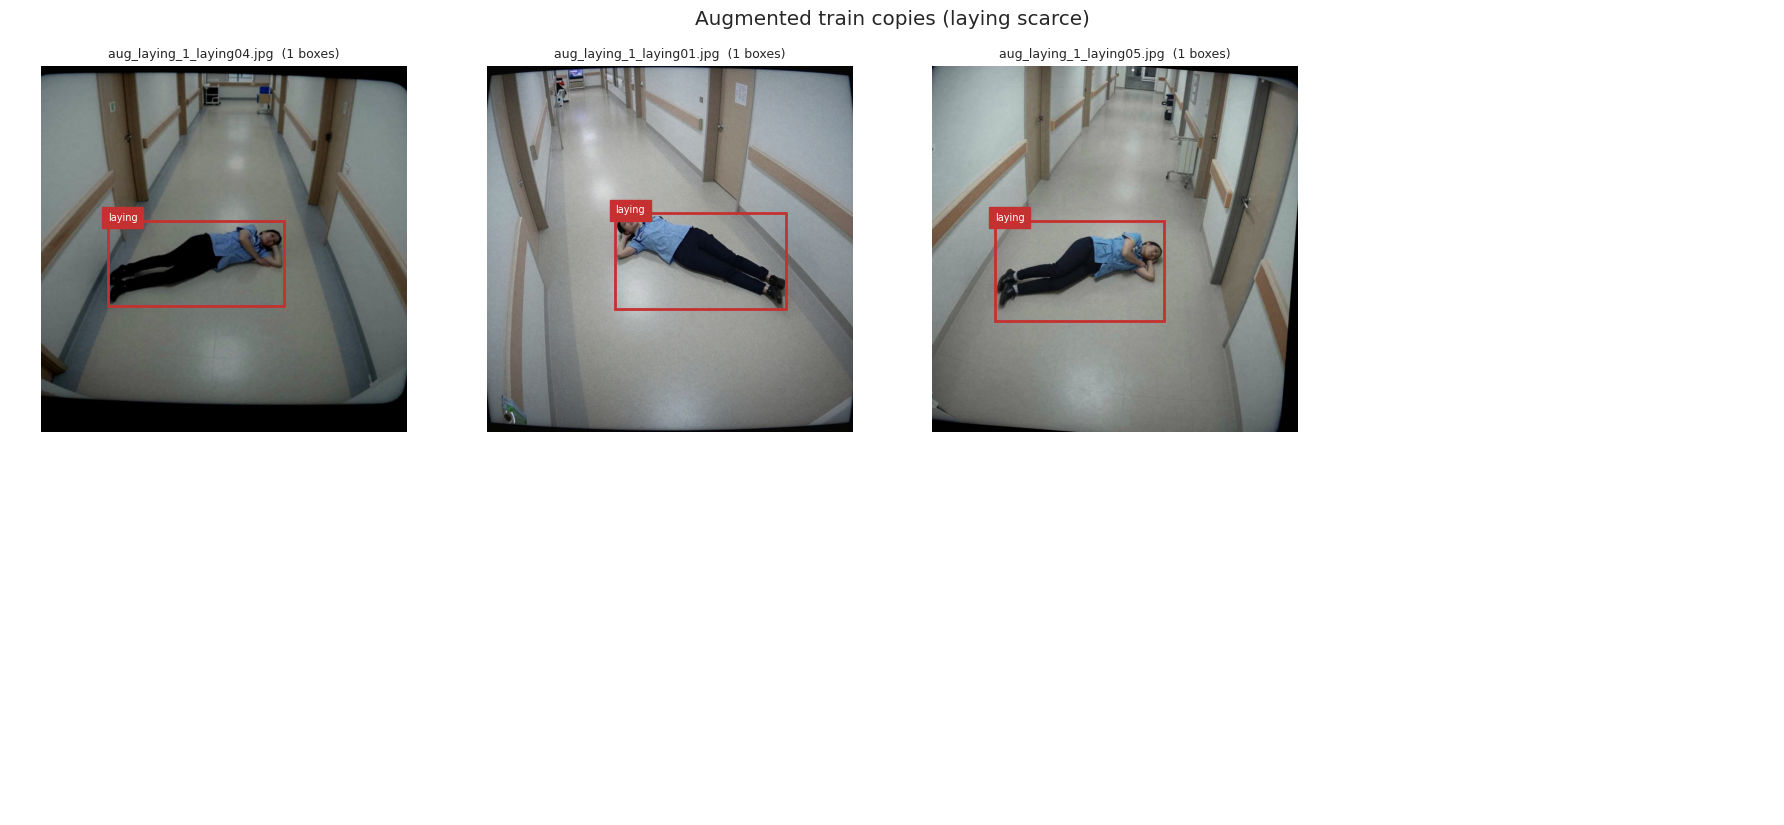

Saved figure: /content/drive/MyDrive/SAMS/results/vision/accident/augmented_examples.png


,count
real train images,77
augmented copies,3
total train images,80


,train,val,test
class,,,
laying,80,17,17
standing,9,1,0


In [ ]:
train_images = manifest[manifest["split"] == "train"]
train_boxes = boxes[boxes["split"] == "train"]
real_counts = class_counts_for_images(TRAIN_IMAGES)
laying_train_boxes = int(real_counts.get(FALL_ID, 0))

scarcity_rows = [{
    "class": FALL_CLASS,
    "boxes in train": laying_train_boxes,
    "target": TARGET_BOXES_PER_CLASS,
    "augment train": laying_train_boxes < TARGET_BOXES_PER_CLASS,
}]
save_table(pd.DataFrame(scarcity_rows).set_index("class"), "train_laying_scarcity")

TRAIN_PATHS = list(TRAIN_IMAGES)
aug_paths = []

if laying_train_boxes < TARGET_BOXES_PER_CLASS:
    def build_augmenter():
        bbox_params = A.BboxParams(format="yolo", label_fields=["class_labels"], min_visibility=0.3, clip=True)
        steps = [
            A.HorizontalFlip(p=0.5),
            A.Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05), rotate=(-8, 8), p=0.6),
            A.RandomBrightnessContrast(brightness_limit=0.25, contrast_limit=0.2, p=0.6),
            A.OneOf([
                A.MotionBlur(blur_limit=5),
                A.GaussianBlur(blur_limit=(3, 5)),
            ], p=0.35),
            A.ImageCompression(quality_range=(40, 85), p=0.35),
        ]
        return A.Compose(steps, bbox_params=bbox_params, seed=SEED)

    augmenter = build_augmenter()
    AUG_IMAGE_DIR = MERGED / "images" / "aug"
    AUG_LABEL_DIR = MERGED / "labels" / "aug"
    for folder in [AUG_IMAGE_DIR, AUG_LABEL_DIR]:
        if folder.exists():
            shutil.rmtree(folder)
        folder.mkdir(parents=True)

    def make_augmented_copy(image_path, copy_name):
        rows = read_labels(label_path_for(image_path))
        boxes_in = []
        labels_in = []
        for row in rows:
            box = clean_box(row[1], row[2], row[3], row[4])
            if box is None:
                continue
            boxes_in.append(box)
            labels_in.append(row[0])
        image = np.array(Image.open(image_path).convert("RGB"))
        try:
            result = augmenter(image=image, bboxes=boxes_in, class_labels=labels_in)
        except ValueError as error:
            print("Skipped", Path(image_path).name, error)
            return None
        new_rows = []
        for class_id, box in zip(result["class_labels"], result["bboxes"]):
            new_rows.append([int(class_id), float(box[0]), float(box[1]), float(box[2]), float(box[3])])
        if not new_rows:
            return None
        target_image = AUG_IMAGE_DIR / f"{copy_name}.jpg"
        Image.fromarray(result["image"]).save(target_image, quality=95)
        write_labels(label_path_for(target_image), new_rows)
        return target_image

    candidates = train_images[train_images[FALL_CLASS] > 0].copy()
    candidates["share"] = candidates[FALL_CLASS] / candidates["boxes"].clip(lower=1)
    candidates = candidates.sort_values("share", ascending=False)
    balanced_laying = laying_train_boxes
    copies_per_image = Counter()
    copy_round = 0
    while balanced_laying < TARGET_BOXES_PER_CLASS and copy_round < MAX_COPIES_PER_IMAGE:
        made_this_round = 0
        for index, row in candidates.iterrows():
            if balanced_laying >= TARGET_BOXES_PER_CLASS:
                break
            if copies_per_image[index] >= MAX_COPIES_PER_IMAGE:
                continue
            copies_per_image[index] += 1
            copy_name = f"aug_laying_{copies_per_image[index]}_{Path(row['image']).stem}"
            new_path = make_augmented_copy(row["image"], copy_name)
            if new_path is None:
                continue
            for new_row in read_labels(label_path_for(new_path)):
                if new_row[0] == FALL_ID:
                    balanced_laying += 1
            aug_paths.append(new_path)
            made_this_round += 1
        if made_this_round == 0:
            break
        copy_round += 1

    TRAIN_PATHS = list(TRAIN_IMAGES) + aug_paths
    preview_images(aug_paths, "Augmented train copies (laying scarce)", "augmented_examples")

train_list_path = write_list("train", TRAIN_PATHS)
composition = pd.DataFrame([{
    "real train images": len(TRAIN_IMAGES),
    "augmented copies": len(aug_paths),
    "total train images": len(TRAIN_PATHS),
}]).T
composition.columns = ["count"]
save_table(composition, "training_set_composition")

split_counters = {
    "train": class_counts_for_images(TRAIN_PATHS),
    "val": class_counts_for_images(VAL_IMAGES),
    "test": class_counts_for_images(TEST_IMAGES),
}
save_table(counts_table(split_counters), "split_class_counts")

### Dataset YAML for Ultralytics

One YAML file points train, val, and test lists. Every experiment uses the same val and test paths.

In [ ]:
def write_data_yaml(name, train_list, val_list, test_list):
    data = {
        "path": str(MERGED),
        "train": str(train_list),
        "val": str(val_list),
        "test": str(test_list),
        "names": CLASS_NAMES,
    }
    path = DATA_DIR / f"fall_{name}.yaml"
    path.write_text(yaml.safe_dump(data, sort_keys=False))
    return path


DATA_YAML = write_data_yaml("main", train_list_path, VAL_LIST, TEST_LIST)
yaml_summary = pd.DataFrame([{
    "train images": len(TRAIN_PATHS),
    "val images": len(VAL_IMAGES),
    "test images": len(TEST_IMAGES),
    "yaml": str(DATA_YAML),
}]).set_index("yaml")
save_table(yaml_summary, "dataset_yaml")

,train images,val images,test images
yaml,,,
/content/SAMS/datasets/vision/accident/fall_main.yaml,80,17,17


## 7. Training setup

### Transfer learning and fine-tuning

Every model starts from YOLOv8 weights pretrained on COCO. The pretrained network already knows people, because `person` is a COCO class. Fine-tuning teaches it to split people into lying and standing. With about 70 training images, starting from pretrained weights is essential.

YOLOv8 has three parts: the **backbone** (layers 0 to 9) turns the image into features, the **neck** mixes features at different scales, and the **head** predicts boxes and classes. Freezing a layer means its weights are not updated during training.

Two ways of fine-tuning are compared:

| Method | What happens |
|--------|--------------|
| single stage | All layers train from the first epoch |
| two stage | **Stage A:** the backbone is frozen (`freeze=10`) and only the neck and head train, for `STAGE_A_EPOCHS`. The new class layers settle without disturbing the pretrained features, which matters most on a small dataset. **Stage B:** every layer is unfrozen and training continues from stage A's best weights with a 10 times lower learning rate and a cosine schedule, so the backbone is adjusted gently |

### Early stopping

After every epoch, Ultralytics scores the model on val. If the val fitness (0.1 times mAP50 plus 0.9 times mAP50-95, over both classes) does not improve for `PATIENCE` epochs, training stops and the best epoch is kept. `MAX_EPOCHS` is only an upper limit.

### Hyperparameters

The optimizer is set to SGD on purpose. With the Ultralytics default `optimizer="auto"`, the learning rate below would be ignored and chosen automatically, which would make the experiments hard to compare.

In [ ]:
BASE_HPARAMS = {
    "optimizer": "SGD",
    "lr0": 0.01,
    "lrf": 0.01,
    "momentum": 0.937,
    "weight_decay": 0.0005,
    "warmup_epochs": 3.0,
    "cos_lr": False,
    "box": 7.5,
    "cls": 0.5,
    "dfl": 1.5,
    "hsv_h": 0.015,
    "hsv_s": 0.7,
    "hsv_v": 0.4,
    "degrees": 0.0,
    "translate": 0.1,
    "scale": 0.5,
    "fliplr": 0.5,
    "flipud": 0.0,
    "mosaic": 1.0,
    "close_mosaic": 5,
}

HPARAM_MEANING = {
    "optimizer": "Update rule. SGD with momentum is the YOLOv8 reference setting",
    "lr0": "Starting learning rate",
    "lrf": "Final learning rate as a fraction of lr0",
    "momentum": "How much of the last update carries into the next one",
    "weight_decay": "Penalty on large weights, reduces overfitting",
    "warmup_epochs": "Epochs where the learning rate ramps up from a small value",
    "cos_lr": "Cosine learning-rate decay instead of linear",
    "box": "Weight of the box position loss",
    "cls": "Weight of the class loss, which separates laying from standing",
    "dfl": "Weight of the distribution focal loss for box edges",
    "hsv_h": "Random hue change during training",
    "hsv_s": "Random saturation change during training",
    "hsv_v": "Random brightness change during training",
    "degrees": "Random rotation during training. Kept at 0, the stored copies already rotate",
    "translate": "Random shift during training",
    "scale": "Random zoom during training",
    "fliplr": "Chance of a left-right flip during training",
    "flipud": "Chance of an upside-down flip. 0, since a CCTV camera never sees the floor at the top",
    "mosaic": "Chance of combining four images into one",
    "close_mosaic": "Turn mosaic off for the last N epochs so the model sees whole images",
}

hparam_rows = []
for name, value in BASE_HPARAMS.items():
    hparam_rows.append({"hyperparameter": name, "value": value, "meaning": HPARAM_MEANING[name]})
save_table(pd.DataFrame(hparam_rows).set_index("hyperparameter"), "hyperparameters_base")

,value,meaning
hyperparameter,,
optimizer,SGD,Update rule. SGD with momentum is the YOLOv8 r...
lr0,0.01,Starting learning rate
lrf,0.01,Final learning rate as a fraction of lr0
momentum,0.937,How much of the last update carries into the n...
weight_decay,0.0005,"Penalty on large weights, reduces overfitting"
warmup_epochs,3.0,Epochs where the learning rate ramps up from a...
cos_lr,False,Cosine learning-rate decay instead of linear
box,7.5,Weight of the box position loss
cls,0.5,"Weight of the class loss, which separates layi..."


### Training and scoring functions

- `train_once` runs one Ultralytics training job.
- `score_model` scores saved weights on a split.
- `per_class_frame` turns Ultralytics metrics into a per-class DataFrame.
- `run_experiment` trains one experiment (single or two stage), reads the training log, scores the best weights on val, and records one row in `LEDGER`.

Reported val metrics:

| Metric | Meaning |
|--------|---------|
| precision | Share of predicted boxes that match a label, both classes |
| recall | Share of labelled boxes that are found, both classes |
| mAP50 | Mean average precision with a 50 percent box overlap needed |
| mAP50-95 | Mean of mAP from 50 to 95 percent overlap. Also rewards tight boxes |
| fall mAP50-95 | mAP50-95 of the `laying` class alone. Used for tie-breaking when overall mAP50-95 is within `WINNER_TOLERANCE` |
| fall recall | Recall of `laying`. A missed fall is the most costly error for SAMS |

In [ ]:
LEDGER = []
EXPERIMENTS = {}


def free_memory():
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()


def read_training_log(run_dir):
    results_csv = Path(run_dir) / "results.csv"
    if not results_csv.is_file():
        return pd.DataFrame()
    log = pd.read_csv(results_csv)
    clean_columns = []
    for column in log.columns:
        clean_columns.append(column.strip())
    log.columns = clean_columns
    return log


def train_once(run_name, data_yaml, weights, imgsz, epochs, freeze, hparams, seed):
    model = YOLO(weights)
    args = dict(hparams)
    args["data"] = str(data_yaml)
    args["epochs"] = epochs
    args["patience"] = PATIENCE
    args["imgsz"] = imgsz
    args["batch"] = BATCH
    args["device"] = YOLO_DEVICE
    args["project"] = str(MODELS_DIR)
    args["name"] = run_name
    args["exist_ok"] = True
    args["seed"] = seed
    args["deterministic"] = True
    args["workers"] = 2
    args["plots"] = True
    args["freeze"] = freeze
    started = time.time()
    model.train(**args)
    elapsed = time.time() - started
    run_dir = Path(model.trainer.save_dir)
    best = run_dir / "weights" / "best.pt"
    del model
    free_memory()
    return run_dir, best, elapsed


def score_model(weights_path, data_yaml, imgsz, split="val", plots=False, name=None):
    model = YOLO(str(weights_path))
    kwargs = {
        "data": str(data_yaml),
        "split": split,
        "imgsz": imgsz,
        "batch": 16,
        "device": YOLO_DEVICE,
        "plots": plots,
        "verbose": False,
    }
    if name is not None:
        kwargs["project"] = str(RESULTS_DIR)
        kwargs["name"] = name
        kwargs["exist_ok"] = True
    metrics = model.val(**kwargs)
    del model
    free_memory()
    return metrics


def per_class_frame(metrics):
    box = metrics.box
    rows = []
    for position, class_id in enumerate(box.ap_class_index):
        rows.append({
            "class": metrics.names[int(class_id)],
            "precision": float(box.p[position]),
            "recall": float(box.r[position]),
            "mAP50": float(box.ap50[position]),
            "mAP50-95": float(box.ap[position]),
        })
    return pd.DataFrame(rows).set_index("class")


def class_metric(per_class, class_name, column):
    """One metric of one class, or NaN if the class has no labels in the scored split."""
    if class_name not in per_class.index:
        return float("nan")
    return float(per_class.loc[class_name, column])


def best_epoch_of(log):
    if log.empty or "metrics/mAP50-95(B)" not in log.columns:
        return None
    fitness = 0.1 * log["metrics/mAP50(B)"] + 0.9 * log["metrics/mAP50-95(B)"]
    return int(log.loc[fitness.idxmax(), "epoch"])


def run_experiment(exp_id, change, data_yaml, weights="yolov8n.pt", imgsz=IMGSZ_BASE,
                   two_stage=False, hparams=None, seed=SEED, group="main"):
    if hparams is None:
        hparams = BASE_HPARAMS

    logs = []
    if two_stage:
        run_dir_a, best_a, time_a = train_once(
            f"{exp_id}_stageA_frozen", data_yaml, weights, imgsz,
            STAGE_A_EPOCHS, FREEZE_LAYERS, hparams, seed,
        )
        stage_b_hparams = dict(hparams)
        stage_b_hparams["lr0"] = hparams["lr0"] / 10
        stage_b_hparams["warmup_epochs"] = 1.0
        stage_b_hparams["cos_lr"] = True
        run_dir, best, time_b = train_once(
            f"{exp_id}_stageB_unfrozen", data_yaml, str(best_a), imgsz,
            MAX_EPOCHS, None, stage_b_hparams, seed,
        )
        elapsed = time_a + time_b
        log_a = read_training_log(run_dir_a)
        log_a["stage"] = "A frozen"
        logs.append(log_a)
        log_b = read_training_log(run_dir)
        log_b["stage"] = "B unfrozen"
        logs.append(log_b)
    else:
        run_dir, best, elapsed = train_once(exp_id, data_yaml, weights, imgsz, MAX_EPOCHS, None, hparams, seed)
        log = read_training_log(run_dir)
        log["stage"] = "single"
        logs.append(log)

    full_log = pd.concat(logs, ignore_index=True)
    full_log["epoch overall"] = np.arange(1, len(full_log) + 1)
    last_log = logs[-1]

    metrics = score_model(best, data_yaml, imgsz)
    per_class = per_class_frame(metrics)
    train_list = yaml.safe_load(Path(data_yaml).read_text())["train"]

    summary = {
        "experiment_id": exp_id,
        "group": group,
        "change": change,
        "weights_in": weights,
        "train images": len(read_list(train_list)),
        "imgsz": imgsz,
        "two_stage": two_stage,
        "optimizer": hparams["optimizer"],
        "seed": seed,
        "epochs_run": len(last_log),
        "best_epoch": best_epoch_of(last_log),
        "stopped_early": len(last_log) < MAX_EPOCHS,
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "map50": float(metrics.box.map50),
        "map50_95": float(metrics.box.map),
        "fall_map50": class_metric(per_class, FALL_CLASS, "mAP50"),
        "fall_map50_95": class_metric(per_class, FALL_CLASS, "mAP50-95"),
        "fall_recall": class_metric(per_class, FALL_CLASS, "recall"),
        "minutes": round(elapsed / 60, 1),
        "best_pt": str(best),
    }
    recipe = {
        "data_yaml": Path(data_yaml),
        "weights": weights,
        "imgsz": imgsz,
        "two_stage": two_stage,
        "hparams": dict(hparams),
    }
    LEDGER.append(summary)
    EXPERIMENTS[exp_id] = {"summary": summary, "per_class": per_class, "log": full_log, "recipe": recipe}

    with (Path(run_dir) / "experiment_summary.json").open("w") as handle:
        json.dump(summary, handle, indent=2)

    shown = ["experiment_id", "change", "epochs_run", "best_epoch", "stopped_early",
             "precision", "recall", "map50", "map50_95", "fall_map50_95", "fall_recall", "minutes"]
    display(pd.DataFrame([summary])[shown].set_index("experiment_id").round(3))
    return summary

## 8. Experiments

Each experiment changes one thing compared with the step before it:

| Id | Change | Question it answers |
|----|--------|---------------------|
| E1 | YOLOv8n at 640 pixels | Baseline |
| E2 | Image size 960 pixels | Do distant people need more pixels? |
| E3 | Two-stage fine-tuning (freeze 10, then unfreeze at lr0/10) | Does a frozen backbone first help on little data? |
| E4 | AdamW lr0=0.001 vs SGD | Which optimizer wins? |
| E5 | YOLOv8s with the winning recipe | Does a larger model help? |

All runs use early stopping (`patience=3`, `max_epochs=25`) and the same val split. The primary score is val mAP50-95; ties within 0.005 go to higher `laying` recall.

### E1. Baseline YOLOv8n at 640 pixels

In [ ]:
run_experiment(
    "fall_e1_baseline",
    "Baseline YOLOv8n, 640 pixels, single-stage SGD",
    data_yaml=DATA_YAML,
)

### E2. Larger image size (960 pixels)

In [ ]:
run_experiment(
    "fall_e2_imgsz960",
    f"YOLOv8n at {IMGSZ_LARGE} pixels",
    data_yaml=DATA_YAML,
    imgsz=IMGSZ_LARGE,
)

e1_score = EXPERIMENTS["fall_e1_baseline"]["summary"][SELECTION_METRIC]
e2_score = EXPERIMENTS["fall_e2_imgsz960"]["summary"][SELECTION_METRIC]
if e2_score > e1_score:
    BEST_IMGSZ = IMGSZ_LARGE
    BEST_BASE_ID = "fall_e2_imgsz960"
else:
    BEST_IMGSZ = IMGSZ_BASE
    BEST_BASE_ID = "fall_e1_baseline"

imgsz_table = pd.DataFrame([
    {"image size": IMGSZ_BASE, f"val {SELECTION_METRIC}": e1_score},
    {"image size": IMGSZ_LARGE, f"val {SELECTION_METRIC}": e2_score},
]).set_index("image size")
save_table(imgsz_table.round(4), "experiment_imgsz_choice")
print("Image size kept from here on:", BEST_IMGSZ)

### E3. Two-stage fine-tuning: freeze 10 layers, then unfreeze at lr0/10

In [ ]:
run_experiment(
    "fall_e3_two_stage",
    f"Freeze {FREEZE_LAYERS} layers for {STAGE_A_EPOCHS} epochs, then unfreeze at lr0/10",
    data_yaml=DATA_YAML,
    imgsz=BEST_IMGSZ,
    two_stage=True,
)

single_score = EXPERIMENTS[BEST_BASE_ID]["summary"][SELECTION_METRIC]
two_stage_score = EXPERIMENTS["fall_e3_two_stage"]["summary"][SELECTION_METRIC]
USE_TWO_STAGE = two_stage_score >= single_score

fine_tune_table = pd.DataFrame([
    {"recipe": "single stage", "experiment": BEST_BASE_ID, SELECTION_METRIC: single_score},
    {"recipe": "two stage", "experiment": "fall_e3_two_stage", SELECTION_METRIC: two_stage_score},
]).set_index("recipe")
save_table(fine_tune_table.round(4), "experiment_two_stage_choice")

FINAL_RECIPE = {
    "data_yaml": DATA_YAML,
    "imgsz": BEST_IMGSZ,
    "two_stage": USE_TWO_STAGE,
    "hparams": dict(BASE_HPARAMS),
}
print("Two-stage fine-tuning kept:", USE_TWO_STAGE)

### E4. Optimizer: AdamW lr0=0.001 vs SGD

In [ ]:
ADAMW_HPARAMS = dict(FINAL_RECIPE["hparams"])
ADAMW_HPARAMS["optimizer"] = "AdamW"
ADAMW_HPARAMS["lr0"] = 0.001
ADAMW_HPARAMS["momentum"] = 0.9

run_experiment(
    "fall_e4_adamw",
    "AdamW lr0=0.001 with the recipe so far",
    data_yaml=FINAL_RECIPE["data_yaml"],
    imgsz=FINAL_RECIPE["imgsz"],
    two_stage=FINAL_RECIPE["two_stage"],
    hparams=ADAMW_HPARAMS,
)

if USE_TWO_STAGE:
    sgd_id = "fall_e3_two_stage"
else:
    sgd_id = BEST_BASE_ID
sgd_score = EXPERIMENTS[sgd_id]["summary"][SELECTION_METRIC]
adamw_score = EXPERIMENTS["fall_e4_adamw"]["summary"][SELECTION_METRIC]

optimizer_table = pd.DataFrame([
    {"optimizer": "SGD", "experiment": sgd_id, SELECTION_METRIC: sgd_score},
    {"optimizer": "AdamW", "experiment": "fall_e4_adamw", SELECTION_METRIC: adamw_score},
]).set_index("optimizer")
save_table(optimizer_table.round(4), "experiment_optimizer_choice")

if adamw_score > sgd_score:
    FINAL_RECIPE["hparams"] = ADAMW_HPARAMS
    OPT_WINNER = "AdamW"
else:
    OPT_WINNER = "SGD"
print("Optimizer kept:", OPT_WINNER)

### E5. YOLOv8s with the winning recipe

In [ ]:
run_experiment(
    "fall_e5_yolov8s",
    "YOLOv8s with best image size, fine-tuning, and optimizer so far",
    data_yaml=FINAL_RECIPE["data_yaml"],
    weights="yolov8s.pt",
    imgsz=FINAL_RECIPE["imgsz"],
    two_stage=FINAL_RECIPE["two_stage"],
    hparams=FINAL_RECIPE["hparams"],
)

## 9. Compare the experiments and choose the model

The winner is the experiment with the highest val `SELECTION_METRIC` (mAP50-95). If another experiment is within `WINNER_TOLERANCE` of it, the one with the higher laying recall wins instead, because a gap that small is within run-to-run noise on about 20 val images, and a missed fall matters most for SAMS.

In [ ]:
ledger_frame = pd.DataFrame(LEDGER)
ledger_columns = ["experiment_id", "group", "change", "weights_in", "train images", "imgsz", "two_stage", "optimizer",
                  "epochs_run", "best_epoch", "stopped_early", "precision", "recall", "map50", "map50_95",
                  "fall_map50", "fall_map50_95", "fall_recall", "minutes"]
ledger_view = ledger_frame[ledger_columns].set_index("experiment_id").round(4)
save_table(ledger_view, "experiment_ledger")

main_ledger = ledger_frame[ledger_frame["group"] == "main"].reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
positions = np.arange(len(main_ledger))
bar_width = 0.2
series = [
    ("precision", "Precision", "#2b6cb0"),
    ("recall", "Recall", "#2f855a"),
    ("map50", "mAP50", "#c05621"),
    ("map50_95", "mAP50-95", "#6b46c1"),
]
for offset, (column, label, color) in enumerate(series):
    axes[0].bar(positions + (offset - 1.5) * bar_width, main_ledger[column], bar_width, label=label, color=color)
axes[0].set_xticks(positions)
axes[0].set_xticklabels(main_ledger["experiment_id"], rotation=25, ha="right")
axes[0].set_ylim(0, 1)
axes[0].set_title("Val scores by experiment, both classes")
axes[0].legend(fontsize=8)

fall_series = [
    ("fall_map50_95", "fall mAP50-95", "#c53030"),
    ("fall_recall", "fall recall", "#dd6b20"),
]
for offset, (column, label, color) in enumerate(fall_series):
    axes[1].bar(positions + (offset - 0.5) * 0.35, main_ledger[column], 0.35, label=label, color=color)
axes[1].set_xticks(positions)
axes[1].set_xticklabels(main_ledger["experiment_id"], rotation=25, ha="right")
axes[1].set_ylim(0, 1)
axes[1].set_title("Val scores of the laying class")
axes[1].legend(fontsize=8)
plt.tight_layout()
save_figure(fig, "experiment_comparison")

### Training curves

Each line is the val mAP50-95 after every epoch, and the val box loss next to it. A line that flattens long before it ends shows where early stopping stepped in. A val loss that rises while training continues is overfitting, which is the main risk on a small dataset. For two-stage runs, stage A and stage B are joined, so the jump where the backbone is unfrozen is visible.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for exp_id, experiment in EXPERIMENTS.items():
    if experiment["summary"]["group"] != "main":
        continue
    log = experiment["log"]
    if "metrics/mAP50-95(B)" in log.columns:
        axes[0].plot(log["epoch overall"], log["metrics/mAP50-95(B)"], label=exp_id)
    if "val/box_loss" in log.columns:
        axes[1].plot(log["epoch overall"], log["val/box_loss"], label=exp_id)
axes[0].set_title("Val mAP50-95 per epoch")
axes[0].set_xlabel("epoch")
axes[1].set_title("Val box loss per epoch")
axes[1].set_xlabel("epoch")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
plt.tight_layout()
save_figure(fig, "training_curves")

In [ ]:
ranked = main_ledger.sort_values(SELECTION_METRIC, ascending=False).reset_index(drop=True)
top_score = ranked.loc[0, SELECTION_METRIC]
close_runs = ranked[ranked[SELECTION_METRIC] >= top_score - WINNER_TOLERANCE]
winner_row = close_runs.sort_values("fall_recall", ascending=False).iloc[0]

WINNER_ID = winner_row["experiment_id"]
WINNER = EXPERIMENTS[WINNER_ID]
BEST_WEIGHTS = Path(WINNER["summary"]["best_pt"])
BEST_IMGSZ_FINAL = int(WINNER["recipe"]["imgsz"])
BEST_DATA = WINNER["recipe"]["data_yaml"]

winner_table = pd.DataFrame([{
    "chosen experiment": WINNER_ID,
    "val mAP50-95": winner_row["map50_95"],
    "val laying recall": winner_row["fall_recall"],
    "val laying mAP50-95": winner_row["fall_map50_95"],
    "runs within tolerance": len(close_runs),
    "image size": BEST_IMGSZ_FINAL,
    "two stage": WINNER["recipe"]["two_stage"],
    "weights": str(BEST_WEIGHTS),
}]).set_index("chosen experiment").round(4)
save_table(winner_table, "experiment_winner")


### Repeat with other seeds

A single training run has some luck in it: the random order of the images, the augmentation draws, and the starting state of the new class layers. On a small dataset that luck is large. The winning recipe is trained again with each seed in `REPEAT_SEEDS`. The mean and standard deviation of the three runs show how much of a gap between experiments could be noise. The second table compares each experiment's gap to the winner with that standard deviation: a gap smaller than it should not be treated as a real difference.

In [ ]:
repeat_ids = [WINNER_ID]
for repeat_seed in REPEAT_SEEDS:
    repeat_id = f"{WINNER_ID}_seed{repeat_seed}"
    run_experiment(
        repeat_id,
        f"Repeat of {WINNER_ID} with seed {repeat_seed}",
        data_yaml=WINNER["recipe"]["data_yaml"],
        weights=WINNER["recipe"]["weights"],
        imgsz=WINNER["recipe"]["imgsz"],
        two_stage=WINNER["recipe"]["two_stage"],
        hparams=WINNER["recipe"]["hparams"],
        seed=repeat_seed,
        group="seed repeat",
    )
    repeat_ids.append(repeat_id)

repeat_rows = []
for exp_id in repeat_ids:
    repeat_rows.append(EXPERIMENTS[exp_id]["summary"])
score_columns = ["precision", "recall", "map50", "map50_95", "fall_map50_95", "fall_recall"]
repeat_frame = pd.DataFrame(repeat_rows)[["experiment_id", "seed"] + score_columns]
save_table(repeat_frame.set_index("experiment_id").round(4), "seed_repeats")

spread = repeat_frame[score_columns].agg(["mean", "std"])
save_table(spread.round(4), "seed_repeats_spread")

seed_std = float(spread.loc["std", SELECTION_METRIC])
noise_rows = []
for _, row in main_ledger.iterrows():
    gap = float(winner_row[SELECTION_METRIC] - row[SELECTION_METRIC])
    noise_rows.append({
        "experiment_id": row["experiment_id"],
        f"val {SELECTION_METRIC}": row[SELECTION_METRIC],
        "gap to winner": gap,
        "seed standard deviation": seed_std,
        "gap larger than seed noise": gap > seed_std,
    })
save_table(pd.DataFrame(noise_rows).set_index("experiment_id").round(4), "experiment_gaps_vs_seed_noise")

## 10. Evaluate the chosen model in detail

Everything in this section uses val only. Test is still untouched.

### 10.1 Per-class scores

In [ ]:
val_metrics = score_model(BEST_WEIGHTS, BEST_DATA, BEST_IMGSZ_FINAL, plots=True, name="fall_best_val")
best_per_class = per_class_frame(val_metrics)

val_box_counts = class_counts_for_images(VAL_IMAGES)
count_column = []
for class_name in best_per_class.index:
    count_column.append(int(val_box_counts.get(NAME_TO_ID[class_name], 0)))
best_per_class.insert(0, "val boxes", count_column)
save_table(best_per_class.round(3), "best_val_per_class")

fig, ax = plt.subplots(figsize=(8, 4.5))
best_per_class[["precision", "recall", "mAP50", "mAP50-95"]].plot(kind="bar", ax=ax)
ax.set_ylim(0, 1)
ax.set_title(f"Val scores per class, {WINNER_ID}")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
save_figure(fig, "best_val_per_class")

### 10.2 Confusion matrix

Columns are the true class, rows are the predicted class, and each column adds up to 1. The `background` row is labels the model missed, and the `background` column is predictions where there was no label. Ultralytics builds this matrix at its own confidence of 0.25, not at the thresholds chosen in 10.4.

The table under it pulls out the errors that matter for SAMS: a fallen person not found or read as standing (a missed fall), and a standing person or an empty spot read as lying (a false alarm).

In [ ]:
matrix = val_metrics.confusion_matrix.matrix
matrix_labels = list(CLASS_NAMES.values()) + ["background"]
confusion = pd.DataFrame(matrix, index=matrix_labels, columns=matrix_labels)
confusion.index.name = "predicted"
confusion.columns.name = "true"
column_totals = confusion.sum(axis=0).replace(0, np.nan)
confusion_share = confusion / column_totals
save_table(confusion.astype(int), "best_val_confusion_counts")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(confusion_share, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Confusion matrix on val, share of each true class")
plt.tight_layout()
save_figure(fig, "best_val_confusion_matrix")

laying_total = confusion["laying"].sum()
standing_total = confusion["standing"].sum()
fall_error_rows = []
if laying_total > 0:
    fall_error_rows.append({"error": "true laying not found (missed fall)", "share of true class": confusion.loc["background", "laying"] / laying_total, "count": int(confusion.loc["background", "laying"])})
    fall_error_rows.append({"error": "true laying read as standing (missed fall)", "share of true class": confusion.loc["standing", "laying"] / laying_total, "count": int(confusion.loc["standing", "laying"])})
if standing_total > 0:
    fall_error_rows.append({"error": "true standing read as laying (false alarm)", "share of true class": confusion.loc["laying", "standing"] / standing_total, "count": int(confusion.loc["laying", "standing"])})
fall_error_rows.append({"error": "laying predicted where nobody is (false alarm)", "share of true class": np.nan, "count": int(confusion.loc["laying", "background"])})
save_table(pd.DataFrame(fall_error_rows).set_index("error").round(3), "best_val_fall_errors")

### 10.3 Precision-recall and F1 curves

Ultralytics records, for every class, precision, recall, and F1 at 1,000 confidence thresholds between 0 and 1. F1 is the balance of precision and recall. These curves are used in 10.4 to choose a threshold per class.

In [ ]:
box_metrics = val_metrics.box
THRESHOLD_GRID = np.asarray(box_metrics.px)
curve_rows = {}
for position, class_id in enumerate(box_metrics.ap_class_index):
    curve_rows[CLASS_NAMES[int(class_id)]] = position

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for class_name, position in curve_rows.items():
    color = CLASS_COLORS[NAME_TO_ID[class_name]]
    axes[0].plot(THRESHOLD_GRID, box_metrics.f1_curve[position], label=class_name, color=color)
    axes[1].plot(THRESHOLD_GRID, box_metrics.r_curve[position], label=class_name, color=color)
    if len(box_metrics.prec_values) > position:
        recall_axis = np.linspace(0, 1, len(box_metrics.prec_values[position]))
        axes[2].plot(recall_axis, box_metrics.prec_values[position], label=class_name, color=color)
axes[0].set_title("F1 against confidence threshold")
axes[0].set_xlabel("confidence threshold")
axes[1].set_title("Recall against confidence threshold")
axes[1].set_xlabel("confidence threshold")
axes[1].axhline(FALL_MIN_RECALL, color="black", linestyle="--", linewidth=1, label="fall recall target")
axes[2].set_title("Precision against recall (IoU 0.5)")
axes[2].set_xlabel("recall")
axes[2].set_ylabel("precision")
for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.legend(fontsize=8)
plt.tight_layout()
save_figure(fig, "best_val_curves")

### 10.4 Confidence thresholds

- `laying` uses the highest threshold that still reaches `FALL_MIN_RECALL` recall on val, because a missed fall costs far more than a false alarm that a person can dismiss. If that recall cannot be reached, the highest-F1 threshold is used.
- `standing` uses the threshold with the highest F1. The live service ignores it, so it only matters for the analysis below.
- Every threshold is kept between 0.05 and 0.80.

The `laying` threshold is written to `metadata.json` as `conf`, the one value the live service passes to `predict`. Because the service keeps only fall-class boxes after `predict`, `conf` is exactly the `laying` threshold there. All thresholds are also written as `class_conf`.

In [ ]:
if FALL_CLASS not in curve_rows:
    raise RuntimeError("The val split has no laying labels, so no fall threshold can be chosen")

CLASS_CONF = {}
threshold_rows = []
for class_name, position in curve_rows.items():
    f1_values = np.asarray(box_metrics.f1_curve[position])
    recall_values = np.asarray(box_metrics.r_curve[position])
    precision_values = np.asarray(box_metrics.p_curve[position])
    chosen_index = int(np.argmax(f1_values))
    rule = "highest F1"
    if class_name in FALL_CLASSES:
        meets_recall = np.where(recall_values >= FALL_MIN_RECALL)[0]
        if len(meets_recall) > 0:
            chosen_index = int(meets_recall.max())
            rule = f"highest threshold with recall at least {FALL_MIN_RECALL}"
        else:
            rule = "highest F1 (recall target not reachable)"
    threshold = float(np.clip(THRESHOLD_GRID[chosen_index], 0.05, 0.80))
    CLASS_CONF[class_name] = round(threshold, 3)
    threshold_rows.append({
        "class": class_name,
        "threshold": round(threshold, 3),
        "rule": rule,
        "precision at threshold": float(precision_values[chosen_index]),
        "recall at threshold": float(recall_values[chosen_index]),
        "F1 at threshold": float(f1_values[chosen_index]),
    })

LIVE_CONF = CLASS_CONF[FALL_CLASS]
save_table(pd.DataFrame(threshold_rows).set_index("class").round(3), "best_val_class_thresholds")
print("Live threshold (conf in metadata.json, the laying threshold):", LIVE_CONF)

### 10.5 Box-by-box analysis on val

The chosen model predicts every val image at a low confidence (0.05). Each prediction is matched to the label of the same class that it overlaps most, as long as the overlap (IoU, intersection over union) is at least `MATCH_IOU`. Each label can be matched once. Predictions below their class threshold from 10.4 are then dropped, which gives the model's behaviour at the live operating point.

From these matches, four analyses are built:

1. Recall by box size and by box shape, to see whether small or foreshortened people are the problem.
2. Bootstrap confidence intervals for precision, recall, and F1 at the thresholds.
3. Confidence calibration: whether a confidence of 0.7 really means right about 70 percent of the time.
4. A gallery of the val images with the most fall errors.

The same two functions are reused on test in section 11, so the live operating point is also measured there.

In [ ]:
def box_iou(box_a, box_b):
    """IoU of two [xc, yc, w, h] boxes in normalised coordinates."""
    a_left = box_a[0] - box_a[2] / 2
    a_right = box_a[0] + box_a[2] / 2
    a_top = box_a[1] - box_a[3] / 2
    a_bottom = box_a[1] + box_a[3] / 2
    b_left = box_b[0] - box_b[2] / 2
    b_right = box_b[0] + box_b[2] / 2
    b_top = box_b[1] - box_b[3] / 2
    b_bottom = box_b[1] + box_b[3] / 2
    overlap_w = max(0.0, min(a_right, b_right) - max(a_left, b_left))
    overlap_h = max(0.0, min(a_bottom, b_bottom) - max(a_top, b_top))
    overlap = overlap_w * overlap_h
    union = box_a[2] * box_a[3] + box_b[2] * box_b[3] - overlap
    if union <= 0:
        return 0.0
    return overlap / union


def confidence_of(prediction):
    return prediction[1]


def match_predictions(label_rows, prediction_rows):
    """Greedy matching, highest confidence first.

    label_rows: [class_id, xc, yc, w, h]
    prediction_rows: [class_id, confidence, xc, yc, w, h]
    Returns which labels were found, and (prediction, is_correct) pairs.
    """
    label_found = [False] * len(label_rows)
    outcomes = []
    for prediction in sorted(prediction_rows, key=confidence_of, reverse=True):
        best_overlap = 0.0
        best_label = -1
        for label_number, label in enumerate(label_rows):
            if label_found[label_number] or label[0] != prediction[0]:
                continue
            overlap = box_iou(prediction[2:6], label[1:5])
            if overlap > best_overlap:
                best_overlap = overlap
                best_label = label_number
        is_correct = best_overlap >= MATCH_IOU
        if is_correct:
            label_found[best_label] = True
        outcomes.append((prediction, is_correct))
    return label_found, outcomes


def predict_images(weights_path, image_paths, imgsz, conf=0.05):
    """Predictions per image path as rows of [class_id, confidence, xc, yc, w, h]."""
    model = YOLO(str(weights_path))
    predictions = {}
    for start in range(0, len(image_paths), 16):
        chunk = image_paths[start:start + 16]
        chunk_paths = []
        for image_path in chunk:
            chunk_paths.append(str(image_path))
        results = model.predict(chunk_paths, conf=conf, imgsz=imgsz, device=YOLO_DEVICE, verbose=False)
        for image_path, result in zip(chunk, results):
            classes = result.boxes.cls.cpu().numpy()
            confidences = result.boxes.conf.cpu().numpy()
            positions = result.boxes.xywhn.cpu().numpy()
            rows = []
            for number in range(len(classes)):
                rows.append([
                    int(classes[number]), float(confidences[number]),
                    float(positions[number][0]), float(positions[number][1]),
                    float(positions[number][2]), float(positions[number][3]),
                ])
            predictions[str(image_path)] = rows
    del model
    free_memory()
    return predictions


def analyse_matches(image_paths, predictions, thresholds):
    """Match predictions to labels at the class thresholds and at 0.05 for calibration."""
    true_positive = np.zeros((len(image_paths), NUM_CLASSES))
    false_positive = np.zeros((len(image_paths), NUM_CLASSES))
    false_negative = np.zeros((len(image_paths), NUM_CLASSES))
    label_records = []
    calibration_records = []
    kept_predictions = {}
    for image_number, image_path in enumerate(image_paths):
        key = str(image_path)
        label_rows = read_labels(label_path_for(image_path))
        all_predictions = predictions[key]

        kept = []
        for prediction in all_predictions:
            if prediction[1] >= thresholds.get(CLASS_NAMES[prediction[0]], 0.25):
                kept.append(prediction)
        kept_predictions[key] = kept

        with Image.open(image_path) as image:
            width, height = image.size
        label_found, outcomes = match_predictions(label_rows, kept)
        for label, found in zip(label_rows, label_found):
            if found:
                true_positive[image_number, label[0]] += 1
            else:
                false_negative[image_number, label[0]] += 1
            aspect = (label[3] * width) / max(label[4] * height, 1e-6)
            label_records.append({
                "image": key,
                "class": CLASS_NAMES[label[0]],
                "size": size_bucket(label[3], label[4], width, height, train_size=BEST_IMGSZ_FINAL),
                "shape": shape_bucket(aspect),
                "found": found,
            })
        for prediction, is_correct in outcomes:
            if not is_correct:
                false_positive[image_number, prediction[0]] += 1

        all_found, all_outcomes = match_predictions(label_rows, all_predictions)
        for prediction, is_correct in all_outcomes:
            calibration_records.append({
                "class": CLASS_NAMES[prediction[0]],
                "confidence": prediction[1],
                "correct": is_correct,
            })
    return {
        "tp": true_positive,
        "fp": false_positive,
        "fn": false_negative,
        "labels": pd.DataFrame(label_records),
        "calibration": pd.DataFrame(calibration_records),
        "kept": kept_predictions,
    }


VAL_PREDICTIONS = predict_images(BEST_WEIGHTS, VAL_IMAGES, BEST_IMGSZ_FINAL)
VAL_MATCHES = analyse_matches(VAL_IMAGES, VAL_PREDICTIONS, CLASS_CONF)
label_results = VAL_MATCHES["labels"]
calibration_results = VAL_MATCHES["calibration"]
true_positive = VAL_MATCHES["tp"]
false_positive = VAL_MATCHES["fp"]
false_negative = VAL_MATCHES["fn"]
print("Val labels checked:", len(label_results))
print("Val predictions checked for calibration:", len(calibration_results))

#### Recall by box size and by box shape

Each cell is the share of labels of that class and size (left) or shape (right) that the model found at its threshold. Low `laying` recall only for `tall` boxes means falls along the camera's line of sight are the weak spot, and more such examples are the fix. Low recall only for `small` boxes points to a larger image size. Empty cells have no labels.

In [ ]:
size_recall = label_results.pivot_table(index="class", columns="size", values="found", aggfunc="mean")
size_recall = size_recall.reindex(index=class_order, columns=["small", "medium", "large"])
size_count = label_results.pivot_table(index="class", columns="size", values="found", aggfunc="count")
size_count = size_count.reindex(index=class_order, columns=["small", "medium", "large"]).fillna(0).astype(int)
size_count.columns = ["small labels", "medium labels", "large labels"]
save_table(pd.concat([size_recall.round(3), size_count], axis=1), "best_val_recall_by_size")

shape_recall = label_results.pivot_table(index="class", columns="shape", values="found", aggfunc="mean")
shape_recall = shape_recall.reindex(index=class_order, columns=["tall", "square", "wide"])
shape_count = label_results.pivot_table(index="class", columns="shape", values="found", aggfunc="count")
shape_count = shape_count.reindex(index=class_order, columns=["tall", "square", "wide"]).fillna(0).astype(int)
shape_count.columns = ["tall labels", "square labels", "wide labels"]
save_table(pd.concat([shape_recall.round(3), shape_count], axis=1), "best_val_recall_by_shape")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(size_recall, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("Recall by box size at the thresholds")
sns.heatmap(shape_recall, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("Recall by box shape at the thresholds")
plt.tight_layout()
save_figure(fig, "best_val_recall_by_size_and_shape")

#### Bootstrap confidence intervals

The val images are resampled with replacement `BOOTSTRAP_ROUNDS` times, and precision, recall, and F1 are recomputed each time. The 2.5 and 97.5 percentiles give a 95 percent interval. With about 20 val images these intervals are wide, which is the honest size of the uncertainty. If two models have overlapping intervals, the difference between them is not reliable.

In [ ]:
bootstrap_rng = np.random.default_rng(SEED)
val_count = len(VAL_IMAGES)
bootstrap_precision = []
bootstrap_recall = []
for _ in range(BOOTSTRAP_ROUNDS):
    sample = bootstrap_rng.integers(0, val_count, val_count)
    tp_sum = true_positive[sample].sum(axis=0)
    fp_sum = false_positive[sample].sum(axis=0)
    fn_sum = false_negative[sample].sum(axis=0)
    with np.errstate(divide="ignore", invalid="ignore"):
        bootstrap_precision.append(tp_sum / (tp_sum + fp_sum))
        bootstrap_recall.append(tp_sum / (tp_sum + fn_sum))
bootstrap_precision = np.array(bootstrap_precision)
bootstrap_recall = np.array(bootstrap_recall)
with np.errstate(divide="ignore", invalid="ignore"):
    bootstrap_f1 = 2 * bootstrap_precision * bootstrap_recall / (bootstrap_precision + bootstrap_recall)

tp_total = true_positive.sum(axis=0)
fp_total = false_positive.sum(axis=0)
fn_total = false_negative.sum(axis=0)
interval_rows = []
for class_name in class_order:
    class_id = NAME_TO_ID[class_name]
    if tp_total[class_id] + fn_total[class_id] == 0:
        continue
    precision = tp_total[class_id] / max(tp_total[class_id] + fp_total[class_id], 1)
    recall = tp_total[class_id] / (tp_total[class_id] + fn_total[class_id])
    interval_rows.append({
        "class": class_name,
        "threshold": CLASS_CONF.get(class_name, np.nan),
        "labels": int(tp_total[class_id] + fn_total[class_id]),
        "precision": precision,
        "precision 2.5%": np.nanpercentile(bootstrap_precision[:, class_id], 2.5),
        "precision 97.5%": np.nanpercentile(bootstrap_precision[:, class_id], 97.5),
        "recall": recall,
        "recall 2.5%": np.nanpercentile(bootstrap_recall[:, class_id], 2.5),
        "recall 97.5%": np.nanpercentile(bootstrap_recall[:, class_id], 97.5),
        "F1 2.5%": np.nanpercentile(bootstrap_f1[:, class_id], 2.5),
        "F1 97.5%": np.nanpercentile(bootstrap_f1[:, class_id], 97.5),
    })
interval_table = pd.DataFrame(interval_rows).set_index("class")
save_table(interval_table.round(3), "best_val_bootstrap_intervals")

fig, ax = plt.subplots(figsize=(8, 4.5))
for column, offset, color in [("precision", -0.1, "#2b6cb0"), ("recall", 0.1, "#2f855a")]:
    lower_error = interval_table[column] - interval_table[f"{column} 2.5%"]
    upper_error = interval_table[f"{column} 97.5%"] - interval_table[column]
    x_positions = np.arange(len(interval_table)) + offset
    ax.errorbar(x_positions, interval_table[column], yerr=[lower_error, upper_error],
                fmt="o", capsize=5, color=color, label=column)
ax.set_xticks(np.arange(len(interval_table)))
ax.set_xticklabels(interval_table.index)
ax.set_ylim(0, 1.05)
ax.set_title("Precision and recall at the thresholds, with 95 percent bootstrap intervals")
ax.legend()
plt.tight_layout()
save_figure(fig, "best_val_bootstrap_intervals")

#### Confidence calibration

Predictions are grouped into ten confidence bins. For each bin, the share of correct predictions is compared with the mean confidence. A well-calibrated model sits on the diagonal. The expected calibration error (ECE) is the average gap, weighted by how many predictions fall in each bin. The live service reports the fall confidence as `lying_score`, so a very over-confident model makes that score look more certain than it is.

In [ ]:
bin_edges = np.linspace(0, 1, 11)


def calibration_table(frame):
    binned = frame.copy()
    binned["bin"] = pd.cut(binned["confidence"], bins=bin_edges, include_lowest=True)
    table = binned.groupby("bin", observed=True).agg(
        predictions=("correct", "count"),
        mean_confidence=("confidence", "mean"),
        share_correct=("correct", "mean"),
    )
    return table


overall_calibration = calibration_table(calibration_results)
save_table(overall_calibration.round(3), "best_val_calibration_bins")

ece_rows = []
reliability_curves = {}
for class_name in ["all classes"] + class_order:
    if class_name == "all classes":
        subset = calibration_results
    else:
        subset = calibration_results[calibration_results["class"] == class_name]
    if subset.empty:
        continue
    table = calibration_table(subset)
    reliability_curves[class_name] = table
    weights = table["predictions"] / table["predictions"].sum()
    gaps = (table["share_correct"] - table["mean_confidence"]).abs()
    ece_rows.append({"class": class_name, "predictions": len(subset), "ECE": float((weights * gaps).sum())})
save_table(pd.DataFrame(ece_rows).set_index("class").round(3), "best_val_calibration_error")

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="perfect calibration")
for class_name, table in reliability_curves.items():
    ax.plot(table["mean_confidence"], table["share_correct"], marker="o", label=class_name)
ax.axvline(LIVE_CONF, color="#c53030", linestyle=":", linewidth=1, label="live threshold")
ax.set_xlabel("mean confidence")
ax.set_ylabel("share correct")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("Reliability diagram on val")
ax.legend(fontsize=8)
plt.tight_layout()
save_figure(fig, "best_val_reliability_diagram")

#### Where the model gets falls wrong

The six val images with the most fall errors: missed `laying` labels plus `laying` predictions with no matching label. Green boxes are the labels, red dashed boxes are the predictions kept at the thresholds. Look for a pattern: a person lying along the line of sight, a person half hidden by furniture, a dark corner, or a label that is itself wrong.

In [ ]:
fall_errors = false_negative[:, FALL_ID] + false_positive[:, FALL_ID]
worst_order = np.argsort(-fall_errors)

gallery = []
for image_number in worst_order[:6]:
    if fall_errors[image_number] > 0:
        gallery.append(image_number)

if not gallery:
    display(pd.DataFrame([{"result": "No fall errors on val at the live threshold"}]))
else:
    fig, axes = plt.subplots(2, 3, figsize=(18, 11))
    for ax in axes.flatten():
        ax.axis("off")
    for ax, image_number in zip(axes.flatten(), gallery):
        image_path = VAL_IMAGES[image_number]
        label_rows = read_labels(label_path_for(image_path))
        draw_boxes(ax, image_path, label_rows, color="#2f855a")
        with Image.open(image_path) as image:
            width, height = image.size
        for prediction in VAL_MATCHES["kept"][str(image_path)]:
            left = (prediction[2] - prediction[4] / 2) * width
            top = (prediction[3] - prediction[5] / 2) * height
            ax.add_patch(patches.Rectangle((left, top), prediction[4] * width, prediction[5] * height,
                                           fill=False, linewidth=1.5, edgecolor="#c53030", linestyle="--"))
            ax.text(left, top + prediction[5] * height, f"{CLASS_NAMES[prediction[0]]} {prediction[1]:.2f}",
                    color="white", fontsize=7, backgroundcolor="#c53030")
        missed = int(false_negative[image_number, FALL_ID])
        extra = int(false_positive[image_number, FALL_ID])
        ax.set_title(f"{image_path.name[:30]}  missed falls: {missed}  false falls: {extra}", fontsize=9)
    plt.tight_layout()
    save_figure(fig, "best_val_fall_errors")

### 10.6 Robustness to bad camera conditions

Every val image is scored as it is, and again after one fixed degradation at a time. Only the image changes, so the labels are the same. The training data is synthetic and clean, while SAMS cameras are not, so this is the best available hint of how the model behaves on real footage. A large drop shows which condition to add more training data for.

| Condition | What it imitates |
|-----------|------------------|
| motion blur | A person falling fast, or camera shake |
| dark | Night shift or a badly lit corner |
| heavy jpeg | A heavily compressed stream |
| low resolution | A distant person on a low-resolution camera |
| sensor noise | A cheap or overheating camera sensor |

Degraded images are saved as PNG, so the degradation is exactly what the model sees.

In [ ]:
CONDITIONS = {
    "clean": None,
    "motion blur": A.MotionBlur(blur_limit=(9, 13), p=1.0),
    "dark": A.RandomBrightnessContrast(brightness_limit=(-0.45, -0.35), contrast_limit=(0.0, 0.0), p=1.0),
    "heavy jpeg": A.ImageCompression(quality_range=(10, 20), p=1.0),
    "low resolution": A.Downscale(scale_range=(0.3, 0.35), p=1.0),
    "sensor noise": A.GaussNoise(std_range=(0.08, 0.12), p=1.0),
}

robust_rows = []
for condition, transform in CONDITIONS.items():
    folder = "robust_" + condition.replace(" ", "_")
    image_dir = MERGED / "images" / folder
    label_dir = MERGED / "labels" / folder
    for directory in [image_dir, label_dir]:
        if directory.exists():
            shutil.rmtree(directory)
        directory.mkdir(parents=True)

    written = []
    for image_path in VAL_IMAGES:
        target = image_dir / f"{image_path.stem}.png"
        pixels = np.array(Image.open(image_path).convert("RGB"))
        if transform is not None:
            pixels = transform(image=pixels)["image"]
        Image.fromarray(pixels).save(target)
        shutil.copy2(label_path_for(image_path), label_dir / f"{image_path.stem}.txt")
        written.append(target)

    list_path = write_list(folder, written)
    data_yaml = write_data_yaml(folder, train_list_path, list_path, list_path)
    metrics = score_model(BEST_WEIGHTS, data_yaml, BEST_IMGSZ_FINAL)
    per_class = per_class_frame(metrics)
    robust_rows.append({
        "condition": condition,
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "mAP50": float(metrics.box.map50),
        "mAP50-95": float(metrics.box.map),
        "fall mAP50-95": class_metric(per_class, FALL_CLASS, "mAP50-95"),
        "fall recall": class_metric(per_class, FALL_CLASS, "recall"),
    })

robust_table = pd.DataFrame(robust_rows).set_index("condition")
clean_fall_score = robust_table.loc["clean", "fall mAP50-95"]
robust_table["fall mAP50-95 drop vs clean"] = clean_fall_score - robust_table["fall mAP50-95"]
save_table(robust_table.round(3), "best_val_robustness")

fig, ax = plt.subplots(figsize=(10, 4))
robust_table[["mAP50-95", "fall mAP50-95", "fall recall"]].plot(kind="bar", ax=ax)
ax.set_ylim(0, 1)
ax.set_title("Val scores under bad camera conditions")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
save_figure(fig, "best_val_robustness")

## 11. Final test, live metadata, export check, model card

### 11.1 Score the chosen model once on test

The chosen weights are copied to `models/vision/accident/best.pt` and scored on the test split. This is the only time test is used. Two views are reported:

- the Ultralytics metrics (precision, recall, mAP), which sweep over all thresholds,
- precision and recall of `laying` at `LIVE_CONF`, the threshold the live service will use, from the same box matching as 10.5.

In [ ]:
PROMOTED = MODELS_DIR / "best.pt"
shutil.copy2(BEST_WEIGHTS, PROMOTED)

TEST_YAML = write_data_yaml("test_final", train_list_path, VAL_LIST, TEST_LIST)
test_metrics = score_model(PROMOTED, TEST_YAML, BEST_IMGSZ_FINAL, split="test")
test_per_class = per_class_frame(test_metrics)

TEST_PREDICTIONS = predict_images(PROMOTED, TEST_IMAGES, BEST_IMGSZ_FINAL)
TEST_MATCHES = analyse_matches(TEST_IMAGES, TEST_PREDICTIONS, CLASS_CONF)
test_tp = TEST_MATCHES["tp"].sum(axis=0)
test_fp = TEST_MATCHES["fp"].sum(axis=0)
test_fn = TEST_MATCHES["fn"].sum(axis=0)
live_precision = float(test_tp[FALL_ID] / max(test_tp[FALL_ID] + test_fp[FALL_ID], 1))
live_recall = float(test_tp[FALL_ID] / max(test_tp[FALL_ID] + test_fn[FALL_ID], 1))

TEST_RESULTS = {
    "images": len(TEST_IMAGES),
    "precision": float(test_metrics.box.mp),
    "recall": float(test_metrics.box.mr),
    "map50": float(test_metrics.box.map50),
    "map50_95": float(test_metrics.box.map),
    "fall_map50": class_metric(test_per_class, FALL_CLASS, "mAP50"),
    "fall_map50_95": class_metric(test_per_class, FALL_CLASS, "mAP50-95"),
    "fall_precision_at_live_conf": live_precision,
    "fall_recall_at_live_conf": live_recall,
    "fall_missed_at_live_conf": int(test_fn[FALL_ID]),
    "false_falls_at_live_conf": int(test_fp[FALL_ID]),
}
test_row = {"test set": "all test images"}
test_row.update(TEST_RESULTS)
save_table(pd.DataFrame([test_row]).set_index("test set").round(4), "final_test")
save_table(test_per_class.round(3), "final_test_per_class")

### 11.2 Metadata for the live service

`accident_inference.py` reads four keys from this file: `model_id` (`model_id`, `load_spec`, and `detect_falls`), `fall_classes` (`detect_falls` keeps only boxes whose normalised class name is in this list), `conf`, and `imgsz` (both passed to `predict` in `detect_falls`). `load_spec` raises an error if any of the four is missing. The other keys are for people and tooling: `class_conf` holds every class threshold from 10.4, and `class_names` is the id-to-name map stored in the weights.

In [ ]:
promoted_model = YOLO(str(PROMOTED))
promoted_names = {}
for class_id, class_name in promoted_model.names.items():
    promoted_names[int(class_id)] = str(class_name)
del promoted_model

dataset_hash = hashlib.sha256(train_list_path.read_bytes()).hexdigest()

metadata = {
    "model_id": f"{Path(WINNER['recipe']['weights']).stem}_fall_sams",
    "fall_classes": FALL_CLASSES,
    "conf": LIVE_CONF,
    "imgsz": BEST_IMGSZ_FINAL,
    "class_names": promoted_names,
    "class_conf": CLASS_CONF,
    "best_experiment_id": WINNER_ID,
    "trained_utc": datetime.now(timezone.utc).isoformat(),
    "dataset_url": DATASET_URL,
    "dataset": {
        "name": DATASET_REPO,
        "url": DATASET_URL,
        "license": "CC BY 4.0",
        "synthetic": True,
        "images_after_deduplication": len(manifest),
        "frame_groups": int(manifest["group"].nunique()),
        "train_images": len(read_list(train_list_path)),
        "val_images": len(VAL_IMAGES),
        "test_images": len(TEST_IMAGES),
        "train_list_sha256": dataset_hash,
    },
    "recipe": {
        "weights_in": WINNER["recipe"]["weights"],
        "two_stage": WINNER["recipe"]["two_stage"],
        "freeze_layers_stage_a": FREEZE_LAYERS,
        "patience": PATIENCE,
        "hyperparameters": WINNER["recipe"]["hparams"],
    },
    "val": {
        "map50": WINNER["summary"]["map50"],
        "map50_95": WINNER["summary"]["map50_95"],
        "fall_map50_95": WINNER["summary"]["fall_map50_95"],
        "fall_recall": WINNER["summary"]["fall_recall"],
        "fall_recall_target": FALL_MIN_RECALL,
    },
    "test": TEST_RESULTS,
    "versions": {
        "ultralytics": ultralytics.__version__,
        "torch": torch.__version__,
        "albumentations": A.__version__,
    },
}
METADATA_PATH = MODELS_DIR / "metadata.json"
with METADATA_PATH.open("w") as handle:
    json.dump(metadata, handle, indent=2, default=str)
print("Metadata written to", METADATA_PATH)

The file is read back and checked the way the live service reads it: the four required keys are present, `conf` and `imgsz` convert to numbers, and every name in `fall_classes`, normalised like `_norm` in the service, matches a class name stored in the weights. If a fall class matched nothing, the service would silently never report a fall, so the notebook stops instead.

In [ ]:
spec = json.loads(METADATA_PATH.read_text())

READ_BY = {
    "model_id": "load_spec, model_id, detect_falls",
    "fall_classes": "load_spec, detect_falls",
    "conf": "load_spec, detect_falls (predict conf)",
    "imgsz": "load_spec, detect_falls (predict imgsz)",
}
check_rows = []
for key, functions in READ_BY.items():
    if key not in spec:
        raise RuntimeError(f"metadata.json is missing {key}, which accident_inference.py requires")
    check_rows.append({"key": key, "value": str(spec[key]), "read by": functions})

conf_value = float(spec["conf"])
imgsz_value = int(spec["imgsz"])
if not 0.0 < conf_value < 1.0:
    raise RuntimeError(f"conf {conf_value} is not between 0 and 1")

weight_names = set()
for class_name in promoted_names.values():
    weight_names.add(norm_name(class_name))
for fall_name in spec["fall_classes"]:
    if norm_name(fall_name) not in weight_names:
        raise RuntimeError(f"fall class {fall_name} is not a class in {PROMOTED}")

check_rows.append({"key": "fall class names found in the weights", "value": str(spec["fall_classes"]), "read by": "detect_falls"})
check_rows.append({"key": "weights file", "value": str(PROMOTED), "read by": "weights_path, get_model"})
save_table(pd.DataFrame(check_rows).set_index("key"), "live_service_contract_check")

### 11.3 Export check

The model is exported to ONNX, the format most deployment runtimes accept. The ONNX file is scored on test again (accuracy should not drop) and both versions are timed on `TIMING_IMAGES` single-image predictions, the way the live stream runs. The val images are cycled to reach that number. Without `onnxruntime-gpu`, the ONNX model runs on the CPU, so its speed shows CPU deployment. The live service itself loads `best.pt`, so ONNX is a deployment option, not a requirement.

In [ ]:
def measure_fps(weights_path, images, imgsz):
    model = YOLO(str(weights_path))
    for image_path in images[:5]:
        model.predict(str(image_path), imgsz=imgsz, device=YOLO_DEVICE, verbose=False)
    started = time.time()
    for image_path in images:
        model.predict(str(image_path), imgsz=imgsz, device=YOLO_DEVICE, verbose=False)
    elapsed = time.time() - started
    del model
    free_memory()
    return len(images) / elapsed


export_model = YOLO(str(PROMOTED))
onnx_path = Path(export_model.export(format="onnx", imgsz=BEST_IMGSZ_FINAL, simplify=True))
del export_model

timing_images = []
for number in range(TIMING_IMAGES):
    timing_images.append(VAL_IMAGES[number % len(VAL_IMAGES)])

export_rows = []
for format_name, weights_path in [("PyTorch", PROMOTED), ("ONNX", onnx_path)]:
    metrics = score_model(weights_path, TEST_YAML, BEST_IMGSZ_FINAL, split="test")
    per_class = per_class_frame(metrics)
    export_rows.append({
        "format": format_name,
        "file": weights_path.name,
        "size MB": round(weights_path.stat().st_size / 1e6, 1),
        "test mAP50": float(metrics.box.map50),
        "test mAP50-95": float(metrics.box.map),
        "test fall mAP50-95": class_metric(per_class, FALL_CLASS, "mAP50-95"),
        "frames per second": measure_fps(weights_path, timing_images, BEST_IMGSZ_FINAL),
    })
save_table(pd.DataFrame(export_rows).set_index("format").round(3), "export_check")

### 11.4 Model card

A one-page summary saved as `model_card.md` next to the weights, so anyone using the model can see where it came from, how well it works, and where it is weak.

In [ ]:
card_lines = []
card_lines.append("# SAMS fall detector")
card_lines.append("")
card_lines.append(f"- Model: {metadata['model_id']} (experiment {WINNER_ID})")
card_lines.append(f"- Trained: {metadata['trained_utc']}")
card_lines.append(f"- Image size: {BEST_IMGSZ_FINAL}")
card_lines.append(f"- Two-stage fine-tuning: {WINNER['recipe']['two_stage']}")
card_lines.append(f"- Optimizer: {WINNER['recipe']['hparams']['optimizer']}, lr0 {WINNER['recipe']['hparams']['lr0']}")
card_lines.append(f"- Training images: {metadata['dataset']['train_images']}, val images: {len(VAL_IMAGES)}, test images: {len(TEST_IMAGES)}")
card_lines.append("")
card_lines.append("## Intended use")
card_lines.append("")
card_lines.append("Detects a person lying on the floor (class laying) in SAMS CCTV frames.")
card_lines.append("monitoring/services/accident_inference.py keeps only laying boxes and marks a tracked worker fallen when one overlaps the worker.")
card_lines.append(f"The live threshold is conf = {LIVE_CONF}, chosen on val as the highest threshold with laying recall at least {FALL_MIN_RECALL}.")
card_lines.append("")
card_lines.append("## Data")
card_lines.append("")
card_lines.append(f"- {DATASET_REPO} ({DATASET_URL}), CC BY 4.0, synthetic renders.")
card_lines.append(f"- {len(manifest)} images after removing duplicates, in {manifest['group'].nunique()} frame groups. Splits are made by group.")
card_lines.append(f"- Training adds {len(background_paths)} background images and up to {len(aug_paths)} augmented copies. Val and test are original images only.")
card_lines.append("")
card_lines.append("## Test results")
card_lines.append("")
card_lines.append("| Metric | Value |")
card_lines.append("|--------|-------|")
for name, value in TEST_RESULTS.items():
    if isinstance(value, float):
        card_lines.append(f"| {name} | {value:.3f} |")
    else:
        card_lines.append(f"| {name} | {value} |")
card_lines.append("")
card_lines.append("## Thresholds")
card_lines.append("")
card_lines.append("| Class | Threshold |")
card_lines.append("|-------|-----------|")
for class_name, threshold in CLASS_CONF.items():
    card_lines.append(f"| {class_name} | {threshold} |")
card_lines.append("")
card_lines.append("## Known limitations")
card_lines.append("")
card_lines.append("- Trained and tested on synthetic images only. Real SAMS footage has not been scored.")
card_lines.append("- The standing class has about ten boxes in the whole dataset, so its scores are rough.")
card_lines.append("- Val and test hold about 20 images each, so every score has a wide confidence interval.")
card_lines.append("- See results/vision/accident/best_val_robustness.csv for how scores drop in poor conditions.")

card_path = MODELS_DIR / "model_card.md"
card_path.write_text("\n".join(card_lines) + "\n")
print("Model card written to", card_path)

## 12. Limitations and next steps

**Known limitations**

1. **Synthetic data only.** Every image is a computer render. Real CCTV footage has different noise, lighting, lenses, and clutter. The robustness test in 12.6 is a hint, not a measurement on real cameras.
2. **Very small dataset.** About 110 images, so val and test hold about 20 images each. The bootstrap intervals in 10.5 and the seed repeats in section 11 show how wide the uncertainty is. Small differences between experiments are not real differences.
3. **Almost no standing people.** About ten `standing` boxes, and every one of them shares its image with a fallen person. The model has never seen a scene with only upright people, so false falls on normal scenes are not measured. The background images reduce that risk but do not replace real negative scenes.
4. **One source.** A leave-one-source-out check is not possible, so how the model handles a new site is unknown.
5. **The live service depends on the person detector too.** `fall_for_box` only marks a worker fallen if the PPE model's person box overlaps the fall box. A lying person that the person detector misses will not raise an alarm, whatever this model does. Any overlap counts (IoU above 0), so a fall box that touches a nearby standing worker can mark that worker fallen.
6. **One threshold in the live service.** `metadata.json` holds `class_conf`, but `accident_inference.py` reads only `conf`. That is enough today, because only `laying` is used.

**Next steps, in order of value**

1. Label 200 to 500 frames from the SAMS cameras, with both fallen and upright people, and add them as a separate test set, then as training data.
2. Put empty frames from the SAMS cameras into `EXTRA_BACKGROUND_DIR` and rerun.
3. Add a second real fall dataset with many standing and walking people, so `standing` can be measured and a leave-one-source-out check becomes possible.
4. Add a minimum overlap (for example IoU 0.3) in `fall_for_box`, and score the full live chain (person detector plus this model) on labelled SAMS clips.
5. Use the review pages in the SAMS app to collect confirmed and rejected fall alerts and feed them back as training data.

In [ ]:
summary_rows = [
    {"item": "chosen experiment", "value": WINNER_ID},
    {"item": "base model", "value": WINNER["recipe"]["weights"]},
    {"item": "image size", "value": BEST_IMGSZ_FINAL},
    {"item": "two-stage fine-tuning", "value": WINNER["recipe"]["two_stage"]},
    {"item": "training images", "value": metadata["dataset"]["train_images"]},
    {"item": "val fall mAP50-95", "value": round(WINNER["summary"]["fall_map50_95"], 4)},
    {"item": "val fall recall", "value": round(WINNER["summary"]["fall_recall"], 4)},
    {"item": "live threshold (conf)", "value": LIVE_CONF},
    {"item": "test fall mAP50-95", "value": round(TEST_RESULTS["fall_map50_95"], 4)},
    {"item": "test fall recall at the live threshold", "value": round(TEST_RESULTS["fall_recall_at_live_conf"], 4)},
    {"item": "test false falls at the live threshold", "value": TEST_RESULTS["false_falls_at_live_conf"]},
    {"item": "weights", "value": str(PROMOTED)},
    {"item": "metadata", "value": str(METADATA_PATH)},
    {"item": "model card", "value": str(card_path)},
    {"item": "tables and charts", "value": str(RESULTS_DIR)},
]
save_table(pd.DataFrame(summary_rows).set_index("item"), "final_summary")